In [1]:
#Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import cv2
from PIL import Image

print(tf.__version__)


2.15.0


In [2]:
#Import Dataset
dataset_path = r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset"

In [3]:
train_path = dataset_path
val_path = dataset_path
test_path = dataset_path

In [4]:
import os

print(train_path)
print(os.path.exists(train_path))

C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset
True


In [5]:
train_path = r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset"

In [6]:
class_names = train_generator.class_indices

print(class_names)

NameError: name 'train_generator' is not defined

In [7]:
#Image Parameters
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 4

In [8]:
#Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8,1.2],
    validation_split=0.2
)

test_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [9]:
#Loading training data
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    subset="training"
)

Found 33866 images belonging to 4 classes.


In [10]:
#Creating Validation Generator
validation_generator = test_datagen.flow_from_directory(
    dataset_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    subset="validation"
)

Found 8464 images belonging to 4 classes.


In [11]:
#Check Classes
class_indices = train_generator.class_indices
class_names = list(class_indices.keys())
print(class_names)

['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


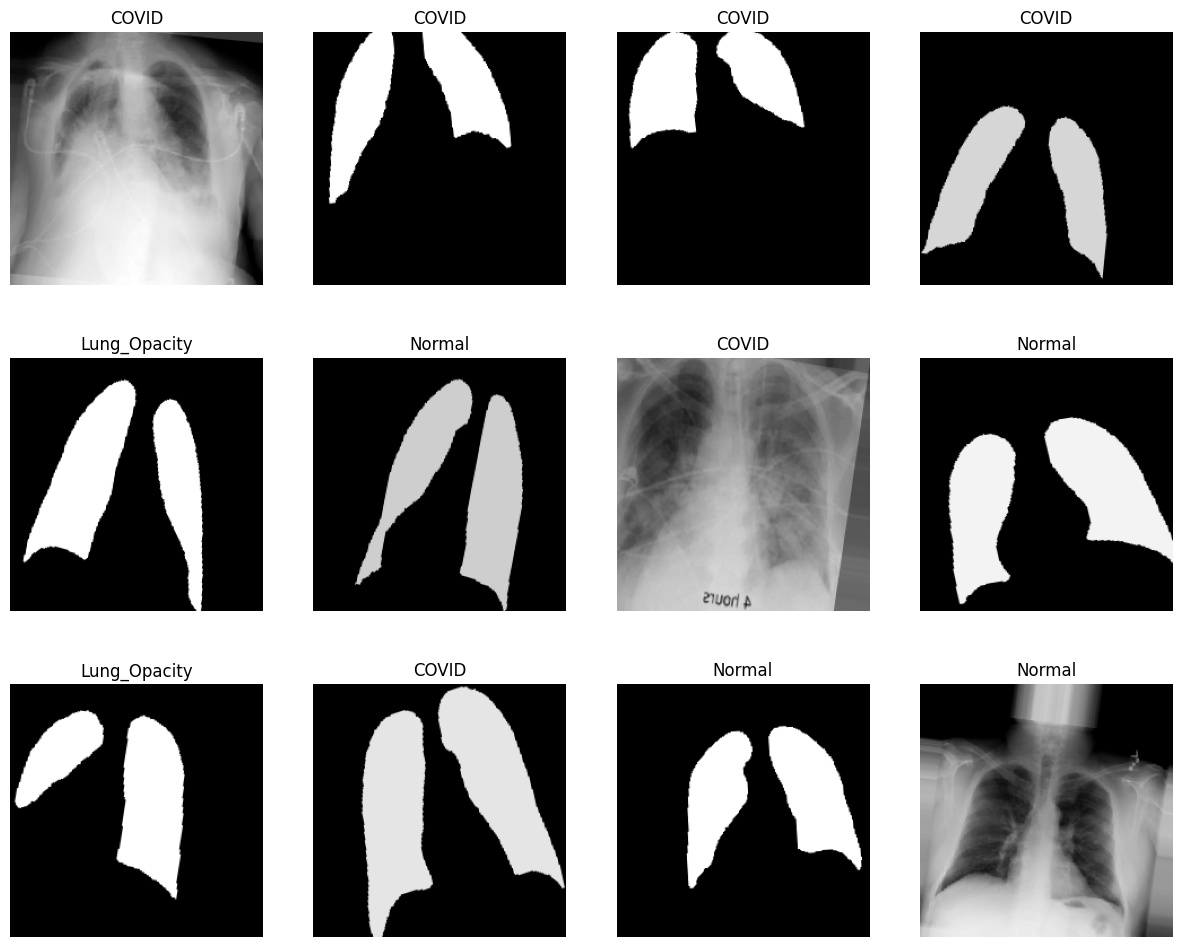

In [12]:
#Display Sample X-rays
images, labels = next(train_generator)

plt.figure(figsize=(15,12))

for i in range(12):

    plt.subplot(3,4,i+1)

    plt.imshow(images[i])

    plt.title(class_names[np.argmax(labels[i])])

    plt.axis("off")

plt.show()

In [13]:
#To handle dataset imbalance
from sklearn.utils import class_weight
labels = train_generator.classes
weights = class_weight.compute_class_weight(

    class_weight="balanced",

    classes=np.unique(labels),

    y=labels

)

class_weights = dict(
    enumerate(weights)
)
class_weights

{0: 1.4632734185966125,
 1: 0.8800935550935551,
 2: 0.5191623742948246,
 3: 3.9342472118959106}

In [14]:
#Import DenseNet121 model components
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

In [15]:
#Load pre trained DenseNet121 which was originally trained in ImageNet
base_model = DenseNet121(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)
base_model.summary()



Model: "densenet121"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 zero_padding2d (ZeroPaddin  (None, 230, 230, 3)          0         ['input_1[0][0]']             
 g2D)                                                                                             
                                                                                                  
 conv1/conv (Conv2D)         (None, 112, 112, 64)         9408      ['zero_padding2d[0][0]']      
                                                                                                  
 conv1/bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1/conv[0][0]

In [16]:
#Freeze DenseNet121 layers
for layer in base_model.layers:
    layer.trainable = False

print(
    "Trainable layers:",
    sum([layer.trainable for layer in base_model.layers])
)

Trainable layers: 0


In [17]:
#Custom clssification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(
    512,
    activation="relu"
)(x)
x = Dropout(
    0.5
)(x)


output = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)


model = Model(

    inputs=base_model.input,

    outputs=output

)

In [18]:
#Displaying model architecture
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 zero_padding2d (ZeroPaddin  (None, 230, 230, 3)          0         ['input_1[0][0]']             
 g2D)                                                                                             
                                                                                                  
 conv1/conv (Conv2D)         (None, 112, 112, 64)         9408      ['zero_padding2d[0][0]']      
                                                                                                  
 conv1/bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1/conv[0][0]']      

In [19]:
for layer in model.layers[-5:]:
    print(layer.name, layer.output_shape)

relu (None, 7, 7, 1024)
global_average_pooling2d (None, 1024)
dense (None, 512)
dropout (None, 512)
dense_1 (None, 4)


In [20]:
#Compile model
model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [21]:
#To prevent overfitting 
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [22]:
#Saving the model
checkpoint = ModelCheckpoint(
    "DenseNet121_ChestXray_Model.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [23]:
#Learnig rate reduction
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

In [24]:
import os

model_path = "DenseNet121_ChestXray_Model.h5"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size:",
          round(os.path.getsize(model_path) / (1024 * 1024), 2),
          "MB")

Model exists: True
Model size: 34.04 MB


In [25]:
import os
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nGPU devices:")
print(tf.config.list_physical_devices('GPU'))

print("\nAll physical devices:")
print(tf.config.list_physical_devices())

print("\nCPU cores:", os.cpu_count())

TensorFlow version: 2.15.0

GPU devices:
[]

All physical devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

CPU cores: 8


In [26]:
print("========== TRAINING INFORMATION ==========")

print("Training images:", train_generator.samples)
print("Validation images:", validation_generator.samples)

print("\nTraining batch size:", train_generator.batch_size)
print("Validation batch size:", validation_generator.batch_size)

print("\nTraining steps per epoch:", len(train_generator))
print("Validation steps:", len(validation_generator))

print("\nImage shape:", train_generator.image_shape)

========== TRAINING INFORMATION ==========
Training images: 33866
Validation images: 8464

Training batch size: 32
Validation batch size: 32

Training steps per epoch: 1059
Validation steps: 265

Image shape: (224, 224, 3)


In [27]:
#Training DenseNet121 model
EPOCHS = 30
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ]

)

Epoch 1/30


 119/1059 [==>...........................] - ETA: 25:00 - loss: 1.3073 - accuracy: 0.3847

KeyboardInterrupt: 

In [ ]:
#Plot accuracy curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Training and Validation Accuracy")

plt.legend()
plt.show()

In [ ]:
#Plot loss curve
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)


plt.xlabel("Epoch")
plt.ylabel("Loss")


plt.title(
    "DenseNet121 Training and Validation Loss"
)


plt.legend()
plt.show()

In [ ]:
#Fine tuning DenseNet121 to improve accuray
for layer in base_model.layers[-50:]:
    layer.trainable=True

#Recompile
model.compile(

    optimizer=Adam(
        learning_rate=1e-5
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [7]:
#Continue Training
fine_history = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=10,

    class_weight=class_weights,

    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]

)

NameError: name 'model' is not defined

In [ ]:
#Save model
model.save(
    "Final_DenseNet121_ChestXray_Model.h5"
)

In [ ]:
#Model Evaluation
# Import libraries required for model evaluation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import evaluation metrics from Scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# LOAD THE BEST TRAINED MODEL

from tensorflow.keras.models import load_model

# Load the model saved during training
model = load_model("Final_DenseNet121_ChestXray_Model.h5")

print("DenseNet121 model loaded successfully.")

In [ ]:
# CHECK TEST DATASET

print("Number of test images:", test_generator.samples)

print("Number of classes:", test_generator.num_classes)

print("Class names:", class_names)

In [ ]:
#Reset test generator
test_generator.reset()

In [ ]:
# Predict the probability for each of the four classes
predictions = model.predict(
    test_generator,
    verbose=1
)

print("Prediction shape:", predictions.shape)

In [ ]:
# CONVERT PROBABILITIES TO CLASS LABELS

# Select the class with the highest probability
y_pred = np.argmax(predictions, axis=1)

# Obtain the actual class labels from the test generator
y_true = test_generator.classes

print("Predicted labels:")
print(y_pred[:20])

print("\nActual labels:")
print(y_true[:20])

In [ ]:
# VERIFY PREDICTION COUNT

print("Number of actual labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

if len(y_true) == len(y_pred):
    print("Prediction count matches test dataset.")
else:
    print("ERROR: Prediction count does not match test dataset.")

In [ ]:
# Test Accuracy
accuracy = accuracy_score(
    y_true,
    y_pred
)

print("Test Accuracy:", round(accuracy, 4))
print("Test Accuracy (%):", round(accuracy * 100, 2), "%")

In [ ]:
#Precision

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro Precision:", round(precision, 4))

In [ ]:
#Recall

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro Recall:", round(recall, 4))

In [ ]:
#F1-Score
f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro F1-Score:", round(f1, 4))

In [ ]:
#Display overall performance
performance = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]

})

# Display scores rounded to four decimal places
performance["Score"] = performance["Score"].round(4)

print(performance)

In [ ]:
#Classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print(report)

In [ ]:
#Disease wise performance table
# Generate classification report as a dictionary
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Create a DataFrame containing only the four disease classes
disease_performance = pd.DataFrame({

    "Disease": class_names,

    "Precision": [
        report_dict[class_name]["precision"]
        for class_name in class_names
    ],

    "Recall": [
        report_dict[class_name]["recall"]
        for class_name in class_names
    ],

    "F1-Score": [
        report_dict[class_name]["f1-score"]
        for class_name in class_names
    ],

    "Support": [
        report_dict[class_name]["support"]
        for class_name in class_names
    ]
})

# Round numerical values
disease_performance[
    ["Precision", "Recall", "F1-Score"]
] = disease_performance[
    ["Precision", "Recall", "F1-Score"]
].round(4)

print(disease_performance)

# Display table

disease_performance

In [ ]:
#confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

In [ ]:
#Visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("DenseNet121 Confusion Matrix")

plt.tight_layout()

plt.show()

In [ ]:
#per class accuracy

per_class_accuracy = []

for i, class_name in enumerate(class_names):

    # True samples belonging to this class
    class_total = np.sum(y_true == i)

    # Correctly classified samples
    class_correct = cm[i, i]

    # Calculate accuracy
    class_accuracy = (
        class_correct / class_total
        if class_total > 0
        else 0
    )

    per_class_accuracy.append(class_accuracy)


# Add the result to the performance table
disease_performance["Accuracy"] = per_class_accuracy

disease_performance["Accuracy"] = (
    disease_performance["Accuracy"].round(4)
)

disease_performance

In [ ]:
#Disease wise F1-score visualization

plt.figure(figsize=(9, 5))

plt.bar(
    disease_performance["Disease"],
    disease_performance["F1-Score"]
)

plt.xlabel("Disease Class")

plt.ylabel("F1-Score")

plt.title("Disease-Wise F1-Score of DenseNet121")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [ ]:
# PRECISION, RECALL AND F1-SCORE COMPARISON

x = np.arange(len(class_names))

width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - width,
    disease_performance["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    disease_performance["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    disease_performance["F1-Score"],
    width,
    label="F1-Score"
)

plt.xlabel("Disease Class")

plt.ylabel("Score")

plt.title(
    "Disease-Wise Precision, Recall and F1-Score"
)

plt.xticks(
    x,
    class_names,
    rotation=20
)

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# SAVE DISEASE-WISE RESULTS
disease_performance.to_csv(
    "DenseNet121_Disease_Performance.csv",
    index=False
)

print(
    "Disease-wise performance saved successfully."
)

In [ ]:
# SAVE OVERALL PERFORMANCE
performance.to_csv(
    "DenseNet121_Overall_Performance.csv",
    index=False
)

print(
    "Overall performance saved successfully."
)

In [ ]:
#Save confusion matrix

cm_dataframe = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_dataframe.to_csv(
    "DenseNet121_Confusion_Matrix.csv"
)

print(
    "Confusion matrix saved successfully."
)

In [28]:
# ============================================================
# LOAD THE PREVIOUSLY SAVED BEST MODEL
# ============================================================

import tensorflow as tf
import os

model_path = "DenseNet121_ChestXray_Model.h5"

if os.path.exists(model_path):

    print("Model found!")
    print("Model size:",
          round(os.path.getsize(model_path) / (1024 * 1024), 2),
          "MB")

    model = tf.keras.models.load_model(model_path)

    print("Model loaded successfully!")

else:
    print("ERROR: Model file not found.")

Model found!
Model size: 34.04 MB
Model loaded successfully!


In [30]:
# ============================================================
# CREATE TEST DATA GENERATOR
# ============================================================

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Test generator created successfully!")

Found 42330 images belonging to 4 classes.
Test generator created successfully!


In [31]:
# ============================================================
# EVALUATE SAVED DENSENET121 MODEL
# ============================================================

print("Evaluating the saved DenseNet121 model...")
print("Please wait. This may take some time on CPU.")

validation_generator.reset()

results = model.evaluate(
    validation_generator,
    verbose=1
)

print("\nEvaluation completed!")

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

Evaluating the saved DenseNet121 model...
Please wait. This may take some time on CPU.
265/265 [==============================] - 371s 1s/step - loss: 0.3715 - accuracy: 0.8622

Evaluation completed!
loss: 0.3715
accuracy: 0.8622


Generating predictions...
265/265 [==============================] - 509s 2s/step

Class names:
['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          COVID     0.8312    0.7628    0.7955      1446
   Lung_Opacity     0.8411    0.8170    0.8289      2404
         Normal     0.8744    0.9220    0.8975      4076
Viral Pneumonia     0.9385    0.8792    0.9079       538

       accuracy                         0.8622      8464
      macro avg     0.8713    0.8452    0.8575      8464
   weighted avg     0.8616    0.8622    0.8613      8464


CONFUSION MATRIX
[[1103  163  169   11]
 [ 121 1964  319    0]
 [ 100  198 3758   20]
 [   3   10   52  473]]


<Figure size 800x600 with 0 Axes>

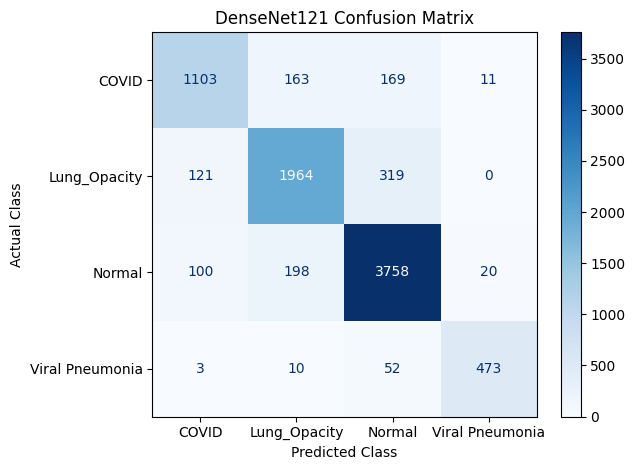

In [32]:
# ============================================================
# DENSENET121 MODEL EVALUATION
# Classification Report + Confusion Matrix
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reset validation generator
validation_generator.reset()

# Generate predictions
print("Generating predictions...")

predictions = model.predict(
    validation_generator,
    verbose=1
)

# Convert probabilities to predicted class numbers
y_pred = np.argmax(predictions, axis=1)

# True labels
y_true = validation_generator.classes

# Class names
class_names = list(validation_generator.class_indices.keys())

print("\nClass names:")
print(class_names)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n============================================================")
print("CLASSIFICATION REPORT")
print("============================================================")

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n============================================================")
print("CONFUSION MATRIX")
print("============================================================")

print(cm)

# ============================================================
# PLOT CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("DenseNet121 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

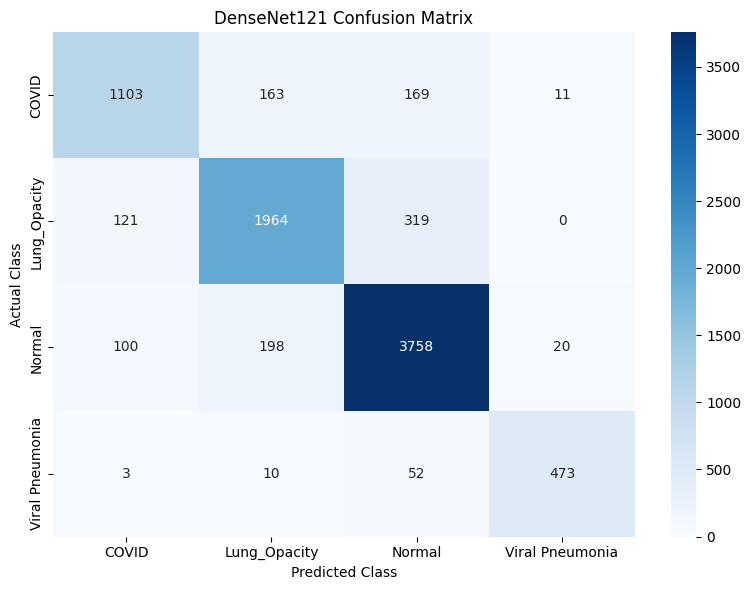

In [33]:
# ============================================================
# CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Class names
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

# Create confusion matrix dataframe
cm_dataframe = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

# Display confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_dataframe,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DenseNet121 Confusion Matrix")

plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

cm_dataframe.to_csv(
    "DenseNet121_Confusion_Matrix.csv"
)

print("Confusion matrix saved successfully.")

Confusion matrix saved successfully.


In [35]:
# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_dataframe = pd.DataFrame(report).transpose()

report_dataframe.to_csv(
    "DenseNet121_Classification_Report.csv"
)

print("Classification report saved successfully.")

Classification report saved successfully.


In [36]:
#FIND THE LAST CONVOLUTIONAL LAYER FOR GRAD-CAM

import tensorflow as tf

print("Searching for convolutional layers...\n")

for layer in model.layers:
    try:
        output_shape = layer.output.shape

        # Grad-CAM requires a spatial feature map
        # such as: (None, height, width, channels)
        if len(output_shape) == 4:
            print(
                "Layer:",
                layer.name,
                "| Output shape:",
                output_shape
            )

    except:
        pass

Searching for convolutional layers...

Layer: input_2 | Output shape: (None, 224, 224, 3)
Layer: zero_padding2d_2 | Output shape: (None, 230, 230, 3)
Layer: conv1/conv | Output shape: (None, 112, 112, 64)
Layer: conv1/bn | Output shape: (None, 112, 112, 64)
Layer: conv1/relu | Output shape: (None, 112, 112, 64)
Layer: zero_padding2d_3 | Output shape: (None, 114, 114, 64)
Layer: pool1 | Output shape: (None, 56, 56, 64)
Layer: conv2_block1_0_bn | Output shape: (None, 56, 56, 64)
Layer: conv2_block1_0_relu | Output shape: (None, 56, 56, 64)
Layer: conv2_block1_1_conv | Output shape: (None, 56, 56, 128)
Layer: conv2_block1_1_bn | Output shape: (None, 56, 56, 128)
Layer: conv2_block1_1_relu | Output shape: (None, 56, 56, 128)
Layer: conv2_block1_2_conv | Output shape: (None, 56, 56, 32)
Layer: conv2_block1_concat | Output shape: (None, 56, 56, 96)
Layer: conv2_block2_0_bn | Output shape: (None, 56, 56, 96)
Layer: conv2_block2_0_relu | Output shape: (None, 56, 56, 96)
Layer: conv2_block2_1_c

Grad-CAM layer selected:
relu
Layer output shape: (None, 7, 7, 1024)

Grad-CAM model created successfully.

Class names:
['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

Searching for one test image from each class...

Images selected for Grad-CAM:
COVID -> COVID-1.png
Lung_Opacity -> Lung_Opacity-1.png
Normal -> Normal-1.png
Viral Pneumonia -> Viral Pneumonia-1.png


GRAD-CAM ANALYSIS: COVID


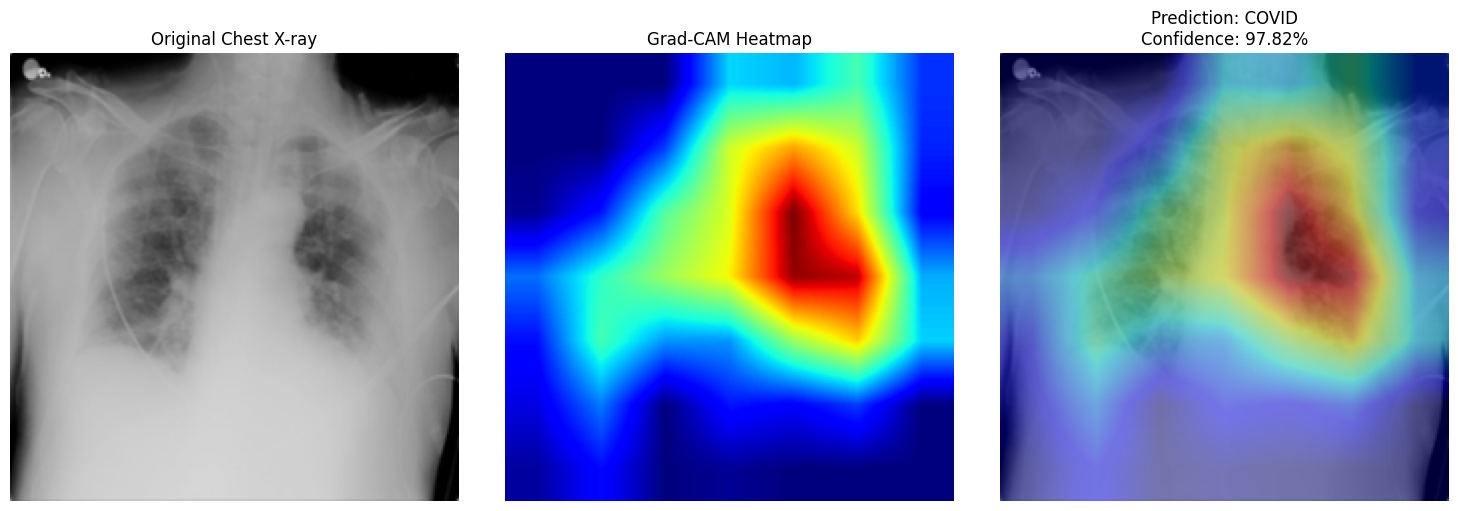


Prediction information
----------------------
Image: COVID-1.png
Predicted class: COVID
Confidence: 97.82%

Class probabilities:
COVID: 97.82%
Lung_Opacity: 2.15%
Normal: 0.03%
Viral Pneumonia: 0.00%


GRAD-CAM ANALYSIS: Lung_Opacity


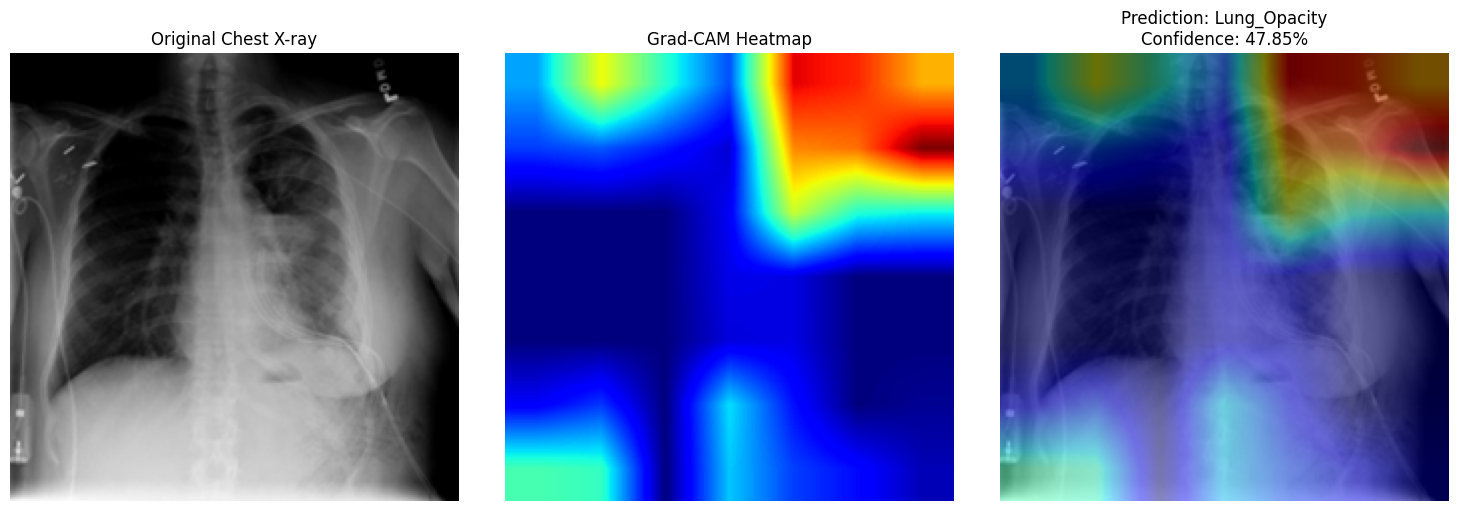


Prediction information
----------------------
Image: Lung_Opacity-1.png
Predicted class: Lung_Opacity
Confidence: 47.85%

Class probabilities:
COVID: 28.62%
Lung_Opacity: 47.85%
Normal: 23.51%
Viral Pneumonia: 0.02%


GRAD-CAM ANALYSIS: Normal


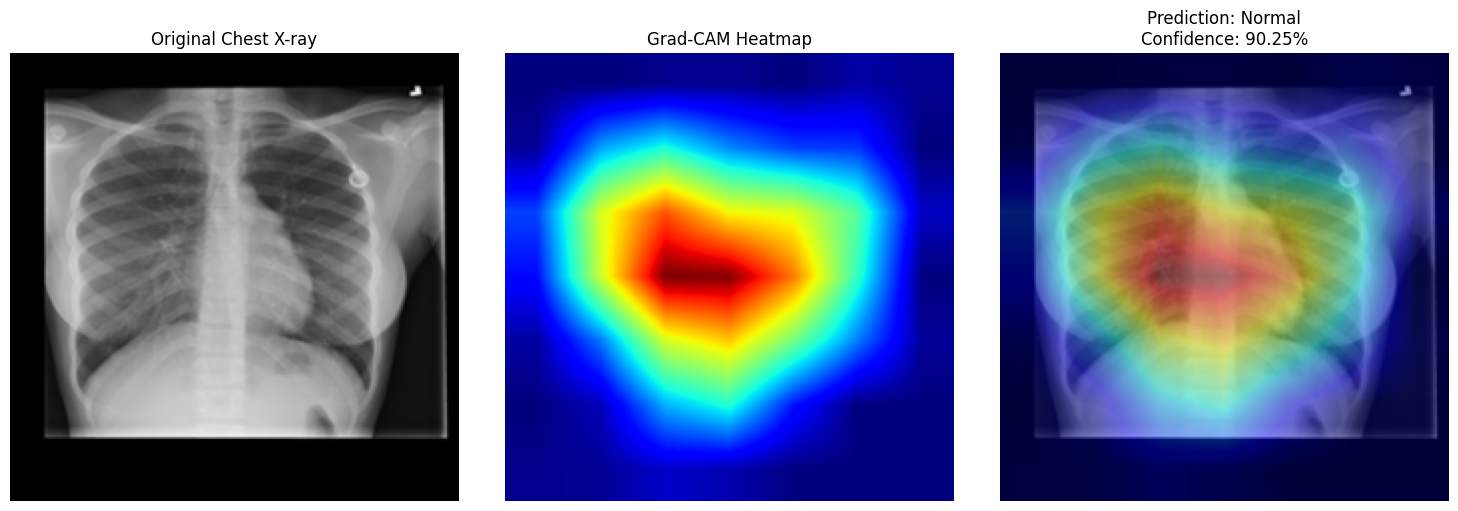


Prediction information
----------------------
Image: Normal-1.png
Predicted class: Normal
Confidence: 90.25%

Class probabilities:
COVID: 6.23%
Lung_Opacity: 3.52%
Normal: 90.25%
Viral Pneumonia: 0.00%


GRAD-CAM ANALYSIS: Viral Pneumonia


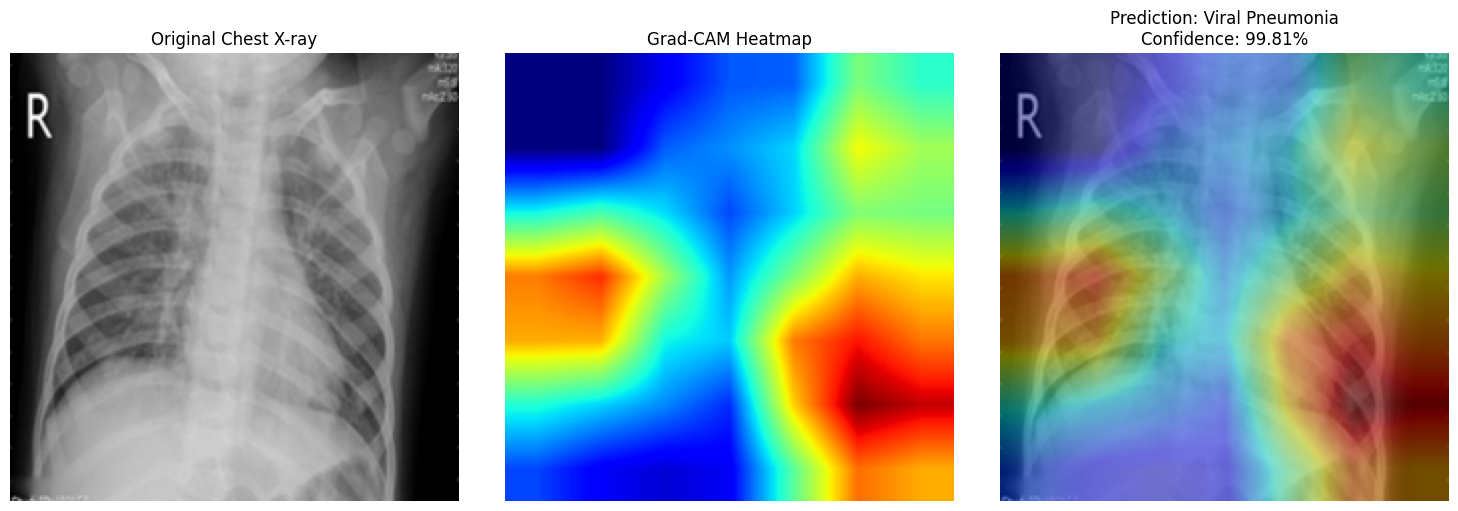


Prediction information
----------------------
Image: Viral Pneumonia-1.png
Predicted class: Viral Pneumonia
Confidence: 99.81%

Class probabilities:
COVID: 0.09%
Lung_Opacity: 0.05%
Normal: 0.06%
Viral Pneumonia: 99.81%


GRAD-CAM ANALYSIS COMPLETED SUCCESSFULLY


In [37]:
# GRAD-CAM EXPLAINABILITY FOR DENSENET121
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# 1. DEFINE THE GRAD-CAM LAYER
# From the previous inspection, the final spatial feature
# layer of DenseNet121 is named "relu".

gradcam_layer_name = "relu"

gradcam_layer = model.get_layer(gradcam_layer_name)

print("Grad-CAM layer selected:")
print(gradcam_layer.name)
print("Layer output shape:", gradcam_layer.output.shape)

# 2. CREATE A MODEL FOR GRAD-CAM
# This model gives us:
# 1. Feature maps from the final convolutional layer
# 2. Final class predictions

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        gradcam_layer.output,
        model.output
    ]
)

print("\nGrad-CAM model created successfully.")

# 3. GRAD-CAM FUNCTION

def make_gradcam_heatmap(image_array, pred_index=None):

    # Convert image to TensorFlow tensor
    image_tensor = tf.cast(image_array, tf.float32)

    # Record operations for gradient calculation
    with tf.GradientTape() as tape:

        # Get convolutional feature maps and predictions
        conv_outputs, predictions = grad_model(image_tensor)

        # If no class is provided, use the predicted class
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        # Probability of the target class
        class_channel = predictions[:, pred_index]

    # Calculate gradients of target class with respect
    # to the final convolutional feature maps
    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    grads = grads[0]

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1)
    )

    # Weight each feature map using the averaged gradients
    conv_outputs = conv_outputs * pooled_grads

    # Average all feature maps
    heatmap = tf.reduce_sum(
        conv_outputs,
        axis=-1
    )

    # Apply ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize between 0 and 1
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()

# 4. FUNCTION TO DISPLAY GRAD-CAM
def display_gradcam(image_path, class_names):

    # Load image
    original_image = Image.open(image_path).convert("RGB")

    # Resize to model input size
    resized_image = original_image.resize(
        (224, 224)
    )

    # Convert image to NumPy array
    image_array = np.array(resized_image)

    # Normalize exactly as used during model training
    input_array = image_array.astype("float32") / 255.0

    # Add batch dimension
    input_array = np.expand_dims(
        input_array,
        axis=0
    )

    # Make prediction
    predictions = model.predict(
        input_array,
        verbose=0
    )

    predicted_index = np.argmax(
        predictions[0]
    )

    predicted_class = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    # Generate Grad-CAM heatmap
    heatmap = make_gradcam_heatmap(
        input_array,
        predicted_index
    )

    # Resize heatmap to original image size
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Display original image
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)

    plt.imshow(
        resized_image
    )

    plt.title(
        "Original Chest X-ray"
    )

    plt.axis("off")
    
    # Display Grad-CAM heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        heatmap_resized,
        cmap="jet"
    )

    plt.title(
        "Grad-CAM Heatmap"
    )

    plt.axis("off")

    # Display Grad-CAM overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        resized_image
    )

    plt.imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

    # Print prediction informations
    print("\nPrediction information")
    print("----------------------")
    print("Image:", os.path.basename(image_path))
    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    print("\nClass probabilities:")

    for i, class_name in enumerate(class_names):
        print(
            f"{class_name}: "
            f"{predictions[0][i] * 100:.2f}%"
        )

    return heatmap_resized, predicted_class, confidence

# 5. GET CLASS NAMES
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

print("\nClass names:")
print(class_names)

# 6. FIND ONE TEST IMAGE FROM EACH CLASS
print("\nSearching for one test image from each class...")


class_images = {}

for class_index, class_name in enumerate(class_names):

    # Find files belonging to this class
    for filepath, label in zip(
        test_generator.filepaths,
        test_generator.classes
    ):

        if label == class_index:

            class_images[class_name] = filepath

            break


print("\nImages selected for Grad-CAM:")

for class_name, filepath in class_images.items():

    print(
        class_name,
        "->",
        os.path.basename(filepath)
    )

# 7. GENERATE GRAD-CAM FOR EACH CLASS
for class_name in class_names:

    print("\n")
    print("=" * 60)
    print(f"GRAD-CAM ANALYSIS: {class_name}")
    print("=" * 60)

    image_path = class_images[class_name]

    heatmap, predicted_class, confidence = display_gradcam(
        image_path,
        class_names
    )


print("\n")
print("=" * 60)
print("GRAD-CAM ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 60)

Grad-CAM output folder: C:\Users\97150\Documents\GradCAM_Results

Saving Grad-CAM: COVID


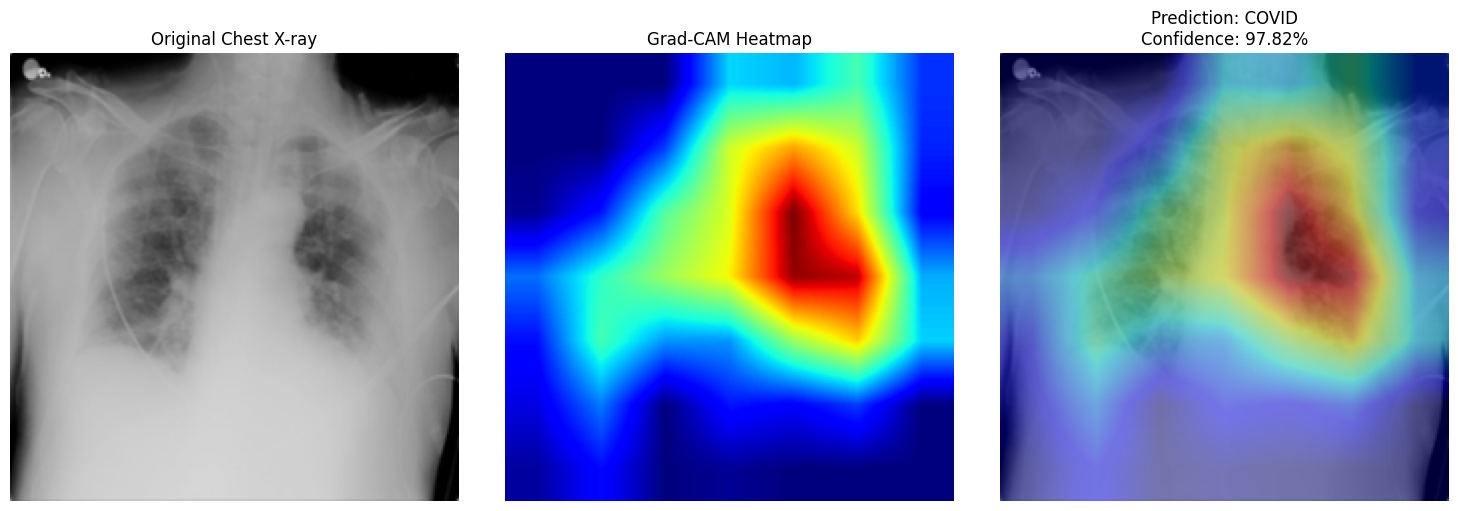


Saved:
GradCAM_Results\GradCAM_COVID.png
Prediction: COVID
Confidence: 97.82%

Saving Grad-CAM: Lung_Opacity


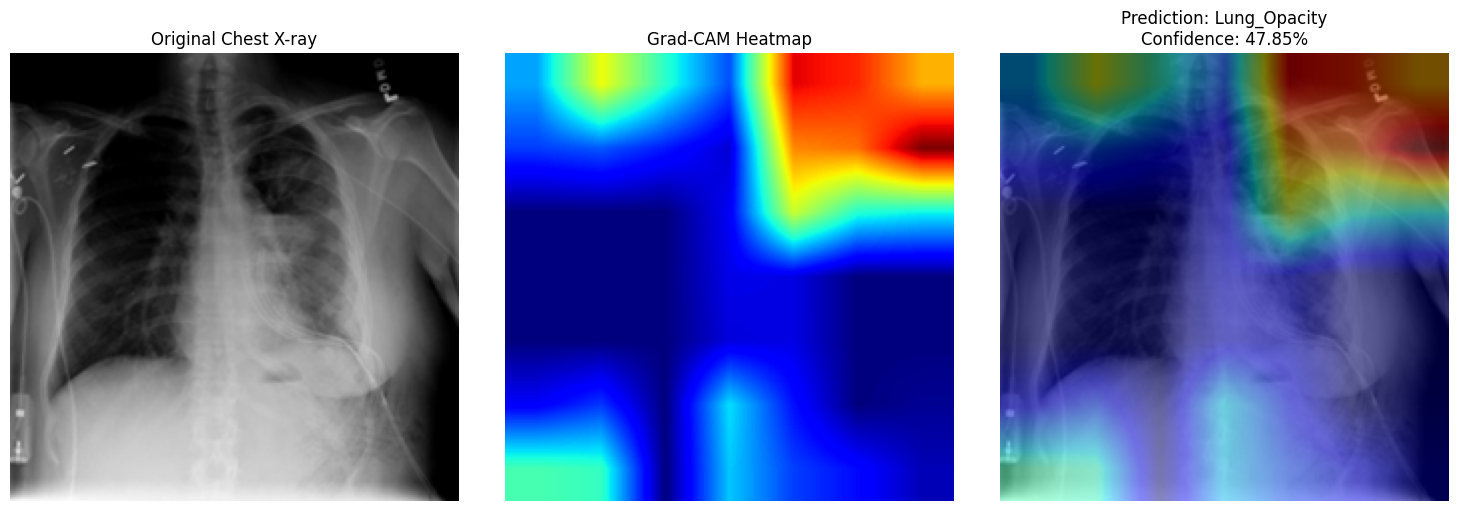


Saved:
GradCAM_Results\GradCAM_Lung_Opacity.png
Prediction: Lung_Opacity
Confidence: 47.85%

Saving Grad-CAM: Normal


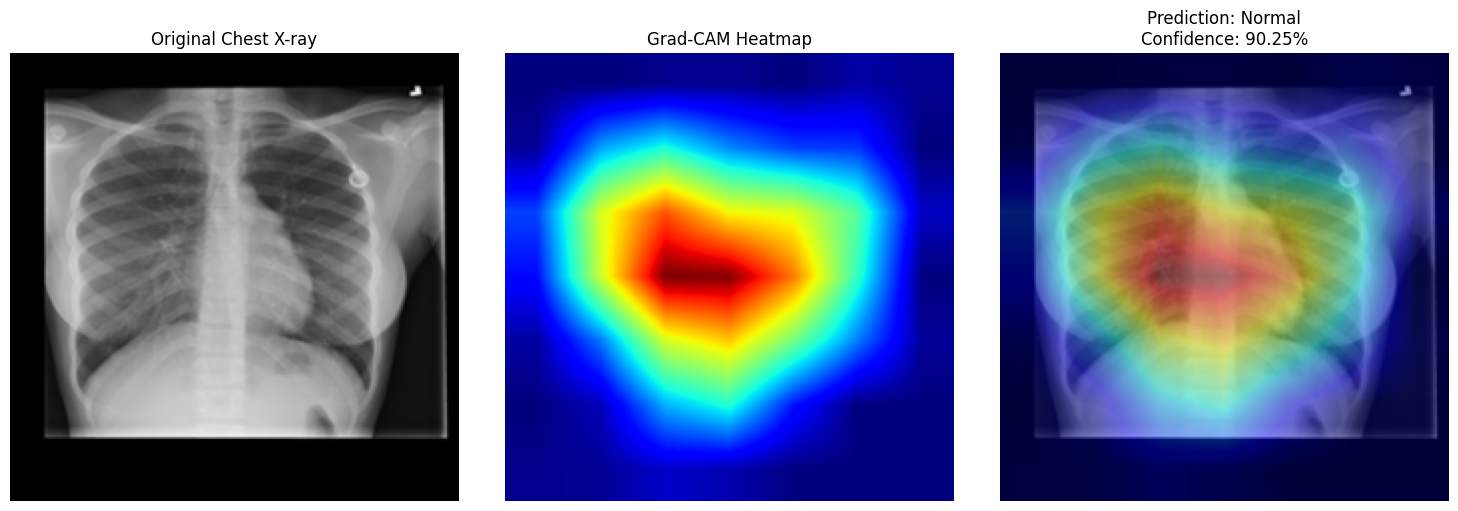


Saved:
GradCAM_Results\GradCAM_Normal.png
Prediction: Normal
Confidence: 90.25%

Saving Grad-CAM: Viral Pneumonia


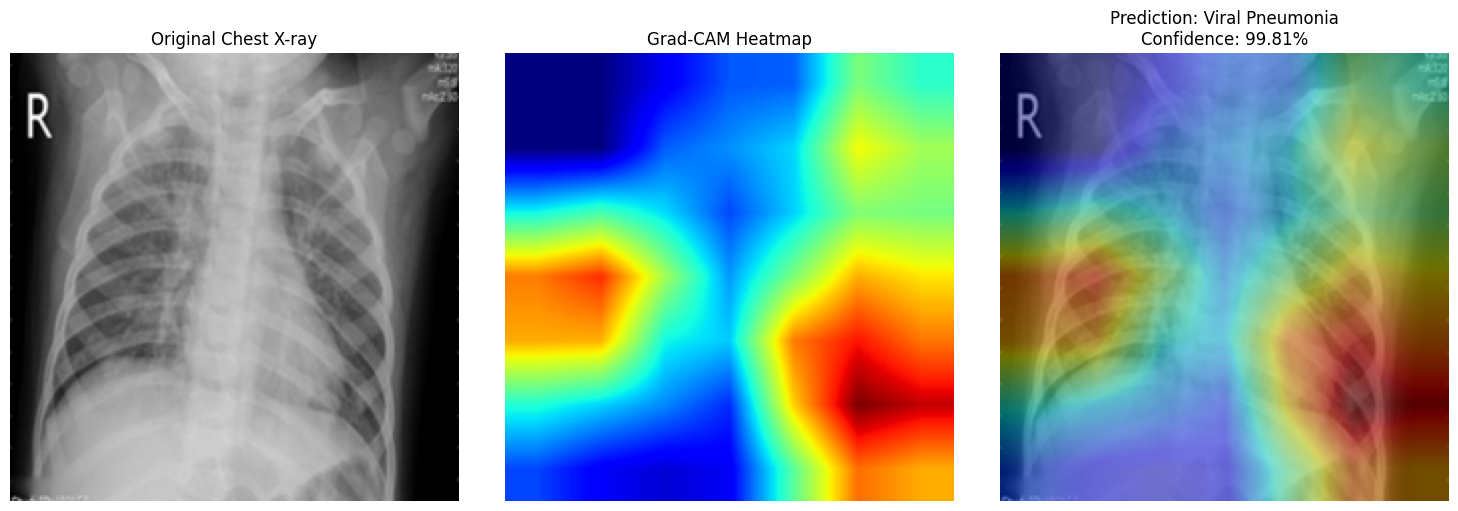


Saved:
GradCAM_Results\GradCAM_Viral_Pneumonia.png
Prediction: Viral Pneumonia
Confidence: 99.81%

ALL GRAD-CAM RESULTS SAVED SUCCESSFULLY


In [38]:
# SAVE GRAD-CAM EXPLANATION IMAGES
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

# Folder where Grad-CAM results will be stored
gradcam_folder = "GradCAM_Results"

os.makedirs(gradcam_folder, exist_ok=True)

print("Grad-CAM output folder:", os.path.abspath(gradcam_folder))

# FUNCTION TO CREATE AND SAVE GRAD-CAM
def save_gradcam_result(image_path, class_names, output_name):

    # Load and preprocess image
    original_image = Image.open(image_path).convert("RGB")

    resized_image = original_image.resize(
        (224, 224)
    )

    image_array = np.array(resized_image).astype("float32") / 255.0

    input_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Prediction
    predictions = model.predict(
        input_array,
        verbose=0
    )

    predicted_index = np.argmax(predictions[0])

    predicted_class = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100
    
    # Generate Grad-CAM
    heatmap = make_gradcam_heatmap(
        input_array,
        predicted_index
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Create figure
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )


    # Original image
    axes[0].imshow(resized_image)
    axes[0].set_title("Original Chest X-ray")
    axes[0].axis("off")


    # Heatmap
    axes[1].imshow(
        heatmap_resized,
        cmap="jet"
    )

    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis("off")


    # Overlay
    axes[2].imshow(resized_image)

    axes[2].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    axes[2].axis("off")
    plt.tight_layout()

    # Save figure
    output_path = os.path.join(
        gradcam_folder,
        output_name
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Print information
    print("\nSaved:")
    print(output_path)

    print("Prediction:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_class, confidence

# GENERATE AND SAVE ONE EXPLANATION FOR EACH CLASS
for class_name in class_names:

    print("\n" + "=" * 60)
    print("Saving Grad-CAM:", class_name)
    print("=" * 60)

    image_path = class_images[class_name]

    safe_name = class_name.replace(
        " ",
        "_"
    )

    output_filename = (
        f"GradCAM_{safe_name}.png"
    )

    save_gradcam_result(
        image_path,
        class_names,
        output_filename
    )


print("\n" + "=" * 60)
print("ALL GRAD-CAM RESULTS SAVED SUCCESSFULLY")
print("=" * 60)

In [39]:
# Conventional baseline CNN model
# This model is used as a baseline for comparison with
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# CREATE CONVENTIONAL CNN
cnn_baseline = models.Sequential([

    # Input
    layers.Input(
        shape=(224, 224, 3)
    ),

    # Convolution Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),
    
    # Convolution Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),
    
    # Feature representation
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(
        0.5
    ),
    
    # Four-class output
    layers.Dense(
        4,
        activation="softmax"
    )
])

# Compile Model
cnn_baseline.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

#Display the model architecture
print("============================================================")
print("CONVENTIONAL CNN BASELINE")
print("============================================================")

cnn_baseline.summary()

CONVENTIONAL CNN BASELINE
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 112, 112, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 56, 56, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (

In [40]:
# Train conventional CNN baseline which helps to compare a conventional CNN against the DensNet121 model

import os
import time
import pandas as pd
import tensorflow as tf

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

# Training settings
CNN_EPOCHS = 10

print("============================================================")
print("CONVENTIONAL CNN TRAINING")
print("============================================================")

print("Maximum epochs:", CNN_EPOCHS)
print("Training images:", train_generator.samples)
print("Validation images:", validation_generator.samples)
print("Batch size:", BATCH_SIZE)

# Reset data generators
train_generator.reset()
validation_generator.reset()

# Callbacks
cnn_checkpoint = ModelCheckpoint(
    "Conventional_CNN_Best.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)


cnn_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)


# Reduce learning rate when validation performance stops improving.
cnn_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-7,
    verbose=1
)


# Save every epoch's results to CSV.
cnn_csv_logger = CSVLogger(
    "Conventional_CNN_training_history.csv",
    append=False
)


#start training timer
training_start_time = time.time()

# Train the conventional CNN
cnn_history = cnn_baseline.fit(
    train_generator,

    validation_data=validation_generator,

    epochs=CNN_EPOCHS,

    callbacks=[
        cnn_checkpoint,
        cnn_early_stopping,
        cnn_reduce_lr,
        cnn_csv_logger
    ],

    verbose=1
)


# Calculate the training time
training_end_time = time.time()

cnn_training_time = (
    training_end_time - training_start_time
)

print("\n============================================================")
print("CONVENTIONAL CNN TRAINING COMPLETED")
print("============================================================")

print(
    f"Training time: "
    f"{cnn_training_time / 60:.2f} minutes"
)


# Display the best of results
best_epoch = (
    cnn_history.history["val_accuracy"].index(
        max(cnn_history.history["val_accuracy"])
    ) + 1
)

best_val_accuracy = max(
    cnn_history.history["val_accuracy"]
)

best_train_accuracy = (
    cnn_history.history["accuracy"][best_epoch - 1]
)

print("\nBest epoch:", best_epoch)

print(
    f"Best training accuracy: "
    f"{best_train_accuracy * 100:.2f}%"
)

print(
    f"Best validation accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)

#Save training history again
cnn_history_dataframe = pd.DataFrame(
    cnn_history.history
)

cnn_history_dataframe.insert(
    0,
    "epoch",
    range(
        1,
        len(cnn_history_dataframe) + 1
    )
)

cnn_history_dataframe.to_csv(
    "Conventional_CNN_training_history.csv",
    index=False
)

print(
    "\nTraining history saved to:"
)

print(
    "Conventional_CNN_training_history.csv"
)


#Verify the saved model
if os.path.exists(
    "Conventional_CNN_Best.h5"
):

    model_size = (
        os.path.getsize(
            "Conventional_CNN_Best.h5"
        ) / (1024 * 1024)
    )

    print(
        "\nBest CNN model saved successfully."
    )

    print(
        f"Model size: {model_size:.2f} MB"
    )

CONVENTIONAL CNN TRAINING
Maximum epochs: 10
Training images: 33866
Validation images: 8464
Batch size: 32
Epoch 1/10
1059/1059 [==============================] - ETA: 0s - loss: 1.2003 - accuracy: 0.4798
Epoch 1: val_accuracy improved from -inf to 0.48157, saving model to Conventional_CNN_Best.h5


C:\Users\97150\AppData\Roaming\Python\Python311\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


1059/1059 [==============================] - 1718s 2s/step - loss: 1.2003 - accuracy: 0.4798 - val_loss: 1.1843 - val_accuracy: 0.4816 - lr: 1.0000e-04
Epoch 2/10
1059/1059 [==============================] - ETA: 0s - loss: 1.1882 - accuracy: 0.4815
Epoch 2: val_accuracy did not improve from 0.48157
1059/1059 [==============================] - 1472s 1s/step - loss: 1.1882 - accuracy: 0.4815 - val_loss: 1.1825 - val_accuracy: 0.4816 - lr: 1.0000e-04
Epoch 3/10
1059/1059 [==============================] - ETA: 0s - loss: 1.1797 - accuracy: 0.4822
Epoch 3: val_accuracy did not improve from 0.48157
Restoring model weights from the end of the best epoch: 1.
1059/1059 [==============================] - 1457s 1s/step - loss: 1.1797 - accuracy: 0.4822 - val_loss: 1.1584 - val_accuracy: 0.4812 - lr: 1.0000e-04
Epoch 3: early stopping

CONVENTIONAL CNN TRAINING COMPLETED
Training time: 77.47 minutes

Best epoch: 1
Best training accuracy: 47.98%
Best validation accuracy: 48.16%

Training history 

In [41]:
#Covetional CNN model evaluation
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

#loading the best CNN model
cnn_model_path = "Conventional_CNN_Best.h5"

print("============================================================")
print("LOADING BEST CONVENTIONAL CNN")
print("============================================================")

if os.path.exists(cnn_model_path):

    cnn_evaluated_model = tf.keras.models.load_model(
        cnn_model_path
    )

    print("CNN model loaded successfully.")

else:

    print("ERROR: CNN model file was not found.")


#Display the model information
print("\nModel parameters:")

print(
    cnn_evaluated_model.count_params()
)


# Reset the validation generator
validation_generator.reset()


#Evaluate CNN
print("\n============================================================")
print("EVALUATING CONVENTIONAL CNN")
print("============================================================")

cnn_results = cnn_evaluated_model.evaluate(
    validation_generator,
    verbose=1
)


#Display the loss and accuracy
print("\n============================================================")
print("CNN EVALUATION RESULTS")
print("============================================================")

for metric_name, metric_value in zip(
    cnn_evaluated_model.metrics_names,
    cnn_results
):

    print(
        f"{metric_name}: {metric_value:.4f}"
    )

#Generate predictions
print("\nGenerating CNN predictions...")

validation_generator.reset()

cnn_predictions = cnn_evaluated_model.predict(
    validation_generator,
    verbose=1
)


# Convert the predictions to class labels
cnn_y_pred = np.argmax(
    cnn_predictions,
    axis=1
)

cnn_y_true = validation_generator.classes


# Define class names
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]


# Calculate accuracy
cnn_accuracy = accuracy_score(
    cnn_y_true,
    cnn_y_pred
)

print("\nCNN Accuracy:")
print(
    f"{cnn_accuracy * 100:.2f}%"
)


#Classification report
print("\n============================================================")
print("CONVENTIONAL CNN CLASSIFICATION REPORT")
print("============================================================")

cnn_report = classification_report(
    cnn_y_true,
    cnn_y_pred,
    target_names=class_names,
    digits=4
)

print(cnn_report)


# Save clssifcation report
cnn_report_dict = classification_report(
    cnn_y_true,
    cnn_y_pred,
    target_names=class_names,
    output_dict=True
)

cnn_report_dataframe = pd.DataFrame(
    cnn_report_dict
).transpose()

cnn_report_dataframe.to_csv(
    "Conventional_CNN_Classification_Report.csv"
)

print(
    "\nCNN classification report saved successfully."
)


#Confusion matrix
cnn_cm = confusion_matrix(
    cnn_y_true,
    cnn_y_pred
)

print("\n============================================================")
print("CONVENTIONAL CNN CONFUSION MATRIX")
print("============================================================")

print(cnn_cm)


#save confusion matrix
cnn_cm_dataframe = pd.DataFrame(
    cnn_cm,
    index=class_names,
    columns=class_names
)

cnn_cm_dataframe.to_csv(
    "Conventional_CNN_Confusion_Matrix.csv"
)

print(
    "\nCNN confusion matrix saved successfully."
)

LOADING BEST CONVENTIONAL CNN
CNN model loaded successfully.

Model parameters:
110276

EVALUATING CONVENTIONAL CNN
265/265 [==============================] - 109s 408ms/step - loss: 1.1843 - accuracy: 0.4816

CNN EVALUATION RESULTS
loss: 1.1843
accuracy: 0.4816

Generating CNN predictions...
265/265 [==============================] - 99s 371ms/step

CNN Accuracy:
48.16%

CONVENTIONAL CNN CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          COVID     0.0000    0.0000    0.0000      1446
   Lung_Opacity     0.0000    0.0000    0.0000      2404
         Normal     0.4816    1.0000    0.6501      4076
Viral Pneumonia     0.0000    0.0000    0.0000       538

       accuracy                         0.4816      8464
      macro avg     0.1204    0.2500    0.1625      8464
   weighted avg     0.2319    0.4816    0.3131      8464


CNN classification report saved successfully.

CONVENTIONAL CNN CONFUSION MATRIX
[[   0    0 1446    0]
 [   0    0 2404    0]

C:\Users\97150\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\97150\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\97150\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\97150\anaconda3\Lib\site-packages\sklearn\metr

In [42]:
# Class distribution and class weights (CNN)
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get training labels
train_labels = train_generator.classes
class_names = list(
    train_generator.class_indices.keys()
)

print("============================================================")
print("TRAINING CLASS DISTRIBUTION")
print("============================================================")

for class_index, class_name in enumerate(class_names):

    count = np.sum(
        train_labels == class_index
    )

    print(
        f"{class_name}: {count} images"
    )
    
# Calculate class weights
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = dict(
    zip(
        np.unique(train_labels),
        class_weights_array
    )
)


print("\n============================================================")
print("CALCULATED CLASS WEIGHTS")
print("============================================================")

for class_index, weight in class_weights.items():

    print(
        f"{class_names[class_index]}: "
        f"{weight:.4f}"
    )

TRAINING CLASS DISTRIBUTION
COVID: 5786 images
Lung_Opacity: 9620 images
Normal: 16308 images
Viral Pneumonia: 2152 images

CALCULATED CLASS WEIGHTS
COVID: 1.4633
Lung_Opacity: 0.8801
Normal: 0.5192
Viral Pneumonia: 3.9342


In [43]:
# CLASS-WEIGHTED CONVENTIONAL CNN
import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)


#Creating a new model
weighted_cnn = models.Sequential([

    # Input layer
    layers.Input(
        shape=(224, 224, 3)
    ),

    # Convolution Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),
    
    # Feature extraction
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(
        0.5
    ),
    
    # Four-class output
    layers.Dense(
        4,
        activation="softmax"
    )
])


#Compile model
weighted_cnn.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)


print("============================================================")
print("CLASS-WEIGHTED CNN CREATED")
print("============================================================")

weighted_cnn.summary()

print(
    "\nTotal parameters:",
    weighted_cnn.count_params()
)


# Define class weights
class_weights = {
    0: 1.4633,   # COVID
    1: 0.8801,   # Lung_Opacity
    2: 0.5192,   # Normal
    3: 3.9342    # Viral Pneumonia
}


print("\n============================================================")
print("CLASS WEIGHTS")
print("============================================================")

for index, weight in class_weights.items():

    print(
        f"{class_names[index]}: {weight:.4f}"
    )


#Prepare geerators
train_generator.reset()
validation_generator.reset()

print("\n============================================================")
print("DATA GENERATORS RESET")
print("============================================================")

print(
    "Training images:",
    train_generator.samples
)

print(
    "Validation images:",
    validation_generator.samples
)

print(
    "Batch size:",
    train_generator.batch_size
)

# Create callbacks
weighted_checkpoint = ModelCheckpoint(

    "Conventional_CNN_Weighted_Best.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

weighted_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

weighted_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

weighted_csv_logger = CSVLogger(
    "Conventional_CNN_Weighted_History.csv",
    append=False
)


# train the class weighted CNN
print("\n============================================================")
print("STARTING CLASS-WEIGHTED CNN TRAINING")
print("============================================================")

print("Maximum epochs: 10")
print("Early stopping patience: 2")
print("Class weighting: ENABLED")
print("============================================================")

training_start = time.time()
weighted_history = weighted_cnn.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        weighted_checkpoint,
        weighted_early_stopping,
        weighted_reduce_lr,
        weighted_csv_logger
    ],

    verbose=1
)


training_end = time.time()


# training time
weighted_training_time = (
    training_end - training_start
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN TRAINING COMPLETED")
print("============================================================")

print(
    f"Training time: "
    f"{weighted_training_time / 60:.2f} minutes"
)


# Best training results
best_weighted_epoch = (
    np.argmax(
        weighted_history.history["val_accuracy"]
    ) + 1
)

best_weighted_train_accuracy = (
    weighted_history.history["accuracy"]
    [best_weighted_epoch - 1]
)

best_weighted_val_accuracy = (
    weighted_history.history["val_accuracy"]
    [best_weighted_epoch - 1]
)

print("\n============================================================")
print("BEST CLASS-WEIGHTED CNN RESULTS")
print("============================================================")

print(
    "Best epoch:",
    best_weighted_epoch
)

print(
    f"Training accuracy: "
    f"{best_weighted_train_accuracy * 100:.2f}%"
)

print(
    f"Validation accuracy: "
    f"{best_weighted_val_accuracy * 100:.2f}%"
)


#Save training history
weighted_history_dataframe = pd.DataFrame(
    weighted_history.history
)

weighted_history_dataframe.insert(
    0,
    "epoch",
    range(
        1,
        len(weighted_history_dataframe) + 1
    )
)

weighted_history_dataframe.to_csv(
    "Conventional_CNN_Weighted_History.csv",
    index=False
)


print(
    "\nTraining history saved successfully."
)

print(
    "File: Conventional_CNN_Weighted_History.csv"
)


# verify the saved model
weighted_model_path = (
    "Conventional_CNN_Weighted_Best.h5"
)

if os.path.exists(weighted_model_path):

    weighted_model_size = (
        os.path.getsize(
            weighted_model_path
        ) / (1024 * 1024)
    )

    print(
        "\nBest class-weighted CNN saved successfully."
    )

    print(
        f"Model size: "
        f"{weighted_model_size:.2f} MB"
    )

else:

    print(
        "\nWARNING: Weighted CNN model file "
        "was not found."
    )

CLASS-WEIGHTED CNN CREATED
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 112, 112, 32)      0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 112, 112, 64)      18496     
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 56, 56, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 56, 56, 128)       73856     
                                                                 
 max_pooling2d_5 (MaxPoolin

C:\Users\97150\AppData\Roaming\Python\Python311\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


1059/1059 [==============================] - 1585s 1s/step - loss: 1.3845 - accuracy: 0.2425 - val_loss: 1.3686 - val_accuracy: 0.4815 - lr: 1.0000e-04
Epoch 2/10
1059/1059 [==============================] - ETA: 0s - loss: 1.3655 - accuracy: 0.2808 
Epoch 2: val_accuracy did not improve from 0.48145
1059/1059 [==============================] - 12777s 12s/step - loss: 1.3655 - accuracy: 0.2808 - val_loss: 1.3419 - val_accuracy: 0.4194 - lr: 1.0000e-04
Epoch 3/10
1059/1059 [==============================] - ETA: 0s - loss: 1.2956 - accuracy: 0.3427
Epoch 3: val_accuracy improved from 0.48145 to 0.52150, saving model to Conventional_CNN_Weighted_Best.h5
1059/1059 [==============================] - 50602s 48s/step - loss: 1.2956 - accuracy: 0.3427 - val_loss: 1.1791 - val_accuracy: 0.5215 - lr: 1.0000e-04
Epoch 4/10
1059/1059 [==============================] - ETA: 0s - loss: 1.2092 - accuracy: 0.4093
Epoch 5: val_accuracy improved from 0.52150 to 0.55825, saving model to Conventional_CNN

In [45]:
#Evaluate the class-weighted conventional CNN
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("LOADING BEST CLASS-WEIGHTED CNN")

weighted_model_path = "Conventional_CNN_Weighted_Best.h5"

if not os.path.exists(weighted_model_path):
    raise FileNotFoundError(
        "Class-weighted CNN model file was not found."
    )

weighted_cnn_best = load_model(weighted_model_path)

print("Class-weighted CNN loaded successfully.")

print("\nModel parameters:")
print(weighted_cnn_best.count_params())


# Reset test generator
test_generator.reset()

print("\n============================================================")
print("TEST GENERATOR")
print("============================================================")

print("Test images:", test_generator.samples)
print("Test batch size:", test_generator.batch_size)
print("Test steps:", len(test_generator))

#Model evaluation
print("\n============================================================")
print("EVALUATING CLASS-WEIGHTED CNN")
print("============================================================")

test_loss, test_accuracy = weighted_cnn_best.evaluate(
    test_generator,
    verbose=1
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN EVALUATION RESULTS")
print("============================================================")

print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Accuracy: {test_accuracy * 100:.2f}%")

#Generate predictions
print("\n============================================================")
print("GENERATING CLASS-WEIGHTED CNN PREDICTIONS")
print("============================================================")

test_generator.reset()

weighted_predictions = weighted_cnn_best.predict(
    test_generator,
    verbose=1
)

weighted_predicted_classes = np.argmax(
    weighted_predictions,
    axis=1
)

weighted_true_classes = test_generator.classes

print("\nPredictions generated successfully.")

print(
    "Number of predictions:",
    len(weighted_predicted_classes)
)

print(
    "Number of true labels:",
    len(weighted_true_classes)
)


#Accuracy
weighted_accuracy = accuracy_score(
    weighted_true_classes,
    weighted_predicted_classes
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN ACCURACY")
print("============================================================")

print(
    f"{weighted_accuracy * 100:.2f}%"
)

#Classification report
print("\n============================================================")
print("CLASS-WEIGHTED CNN CLASSIFICATION REPORT")
print("============================================================")

weighted_report = classification_report(
    weighted_true_classes,
    weighted_predicted_classes,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(weighted_report)

#Save the classification report
weighted_report_path = (
    "Conventional_CNN_Weighted_Classification_Report.txt"
)

with open(
    weighted_report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "CLASS-WEIGHTED CONVENTIONAL CNN "
        "CLASSIFICATION REPORT\n"
    )

    file.write("=" * 60 + "\n\n")

    file.write(
        f"Test Accuracy: "
        f"{weighted_accuracy * 100:.2f}%\n\n"
    )

    file.write(weighted_report)
print(
    "\nClassification report saved successfully."
)

print(
    "File:",
    weighted_report_path
)

#Confusion Matrix
weighted_cm = confusion_matrix(
    weighted_true_classes,
    weighted_predicted_classes
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN CONFUSION MATRIX")
print("============================================================")

print(weighted_cm)

# Save confusion matrix
weighted_cm_path = (
    "Conventional_CNN_Weighted_Confusion_Matrix.csv"
)

np.savetxt(
    weighted_cm_path,
    weighted_cm,
    delimiter=",",
    fmt="%d"
)

print(
    "\nConfusion matrix saved successfully."
)

print(
    "File:",
    weighted_cm_path
)


print("\n============================================================")
print("CLASS-WEIGHTED CNN EVALUATION COMPLETED")
print("============================================================")

LOADING BEST CLASS-WEIGHTED CNN
Class-weighted CNN loaded successfully.

Model parameters:
110276

TEST GENERATOR
Test images: 42330
Test batch size: 32
Test steps: 1323

EVALUATING CLASS-WEIGHTED CNN
1323/1323 [==============================] - 414s 312ms/step - loss: 1.0871 - accuracy: 0.5550

CLASS-WEIGHTED CNN EVALUATION RESULTS
Loss: 1.0871
Accuracy: 0.5550
Accuracy: 55.50%

GENERATING CLASS-WEIGHTED CNN PREDICTIONS
1323/1323 [==============================] - 381s 287ms/step

Predictions generated successfully.
Number of predictions: 42330
Number of true labels: 42330

CLASS-WEIGHTED CNN ACCURACY
55.50%

CLASS-WEIGHTED CNN CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          COVID     0.3667    0.1363    0.1988      7232
   Lung_Opacity     0.5286    0.5519    0.5400     12024
         Normal     0.6676    0.6604    0.6640     20384
Viral Pneumonia     0.3482    0.8959    0.5015      2690

       accuracy                         0.5550     423

In [46]:
validation_generator.samples

8464

In [47]:
# Evaluate class-weighted CNN on held out validation set
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("============================================================")
print("CLASS-WEIGHTED CNN - HELD-OUT VALIDATION EVALUATION")
print("============================================================")

# Reset validation generator
validation_generator.reset()

print("\nValidation images:", validation_generator.samples)
print("Validation batch size:", validation_generator.batch_size)
print("Validation steps:", len(validation_generator))

# Model evaluation
print("\n============================================================")
print("EVALUATING CLASS-WEIGHTED CNN")
print("============================================================")

val_loss, val_accuracy = weighted_cnn_best.evaluate(
    validation_generator,
    verbose=1
)

print("\n============================================================")
print("VALIDATION RESULTS")
print("============================================================")

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")


# Generate predictions
print("\n============================================================")
print("GENERATING VALIDATION PREDICTIONS")
print("============================================================")

validation_generator.reset()

weighted_val_predictions = weighted_cnn_best.predict(
    validation_generator,
    verbose=1
)

weighted_val_predicted_classes = np.argmax(
    weighted_val_predictions,
    axis=1
)

weighted_val_true_classes = validation_generator.classes

print("\nPredictions generated successfully.")

print(
    "Number of predictions:",
    len(weighted_val_predicted_classes)
)

print(
    "Number of true labels:",
    len(weighted_val_true_classes)
)


# Accuracy
weighted_val_accuracy = accuracy_score(
    weighted_val_true_classes,
    weighted_val_predicted_classes
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN VALIDATION ACCURACY")
print("============================================================")

print(
    f"{weighted_val_accuracy * 100:.2f}%"
)


# Classification report
print("\n============================================================")
print("CLASS-WEIGHTED CNN CLASSIFICATION REPORT")
print("============================================================")

weighted_val_report = classification_report(
    weighted_val_true_classes,
    weighted_val_predicted_classes,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(weighted_val_report)


# Save classification report
weighted_val_report_path = (
    "Conventional_CNN_Weighted_Validation_Classification_Report.txt"
)

with open(
    weighted_val_report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "CLASS-WEIGHTED CONVENTIONAL CNN\n"
        "HELD-OUT VALIDATION CLASSIFICATION REPORT\n"
    )

    file.write("=" * 60 + "\n\n")

    file.write(
        f"Validation Loss: {val_loss:.4f}\n"
    )

    file.write(
        f"Validation Accuracy: "
        f"{weighted_val_accuracy * 100:.2f}%\n\n"
    )

    file.write(weighted_val_report)

print(
    "\nClassification report saved:"
)

print(weighted_val_report_path)

#Confusion Matrix
weighted_val_cm = confusion_matrix(
    weighted_val_true_classes,
    weighted_val_predicted_classes
)

print("\n============================================================")
print("CLASS-WEIGHTED CNN CONFUSION MATRIX")
print("============================================================")

print(weighted_val_cm)


# Save confusion matrix
weighted_val_cm_path = (
    "Conventional_CNN_Weighted_Validation_Confusion_Matrix.csv"
)

np.savetxt(
    weighted_val_cm_path,
    weighted_val_cm,
    delimiter=",",
    fmt="%d"
)

print(
    "\nConfusion matrix saved:"
)

print(weighted_val_cm_path)


print("\n============================================================")
print("HELD-OUT VALIDATION EVALUATION COMPLETED")
print("============================================================")

CLASS-WEIGHTED CNN - HELD-OUT VALIDATION EVALUATION

Validation images: 8464
Validation batch size: 32
Validation steps: 265

EVALUATING CLASS-WEIGHTED CNN
265/265 [==============================] - 85s 318ms/step - loss: 1.0327 - accuracy: 0.5818

VALIDATION RESULTS
Validation Loss: 1.0327
Validation Accuracy: 0.5818
Validation Accuracy: 58.18%

GENERATING VALIDATION PREDICTIONS
265/265 [==============================] - 79s 296ms/step

Predictions generated successfully.
Number of predictions: 8464
Number of true labels: 8464

CLASS-WEIGHTED CNN VALIDATION ACCURACY
58.18%

CLASS-WEIGHTED CNN CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          COVID     0.4182    0.3077    0.3546      1446
   Lung_Opacity     0.5663    0.6535    0.6068      2404
         Normal     0.7224    0.5976    0.6541      4076
Viral Pneumonia     0.3764    0.8773    0.5268       538

       accuracy                         0.5818      8464
      macro avg     0.5208    0.6

In [49]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nCSV files in the current folder:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current working directory:
C:\Users\97150\Documents

CSV files in the current folder:
Conventional_CNN_Classification_Report.csv
Conventional_CNN_Confusion_Matrix.csv
Conventional_CNN_training_history.csv
Conventional_CNN_Weighted_Confusion_Matrix.csv
Conventional_CNN_Weighted_History.csv
Conventional_CNN_Weighted_Validation_Confusion_Matrix.csv
DenseNet121_Classification_Report.csv
DenseNet121_Confusion_Matrix.csv


In [50]:
import pandas as pd
import os

original_history_path = "Conventional_CNN_training_history.csv"
weighted_history_path = "Conventional_CNN_Weighted_History.csv"

print("Checking history files...")

print(
    "Original CNN history exists:",
    os.path.exists(original_history_path)
)

print(
    "Weighted CNN history exists:",
    os.path.exists(weighted_history_path)
)

# Load both histories
original_history_df = pd.read_csv(
    original_history_path
)

weighted_history_df = pd.read_csv(
    weighted_history_path
)

print("\nOriginal CNN history:")
print(original_history_df)

print("\nClass-weighted CNN history:")
print(weighted_history_df)

Checking history files...
Original CNN history exists: True
Weighted CNN history exists: True

Original CNN history:
   epoch      loss  accuracy  val_loss  val_accuracy      lr
0      1  1.200268  0.479773  1.184281      0.481569  0.0001
1      2  1.188171  0.481545  1.182509      0.481569  0.0001
2      3  1.179672  0.482195  1.158427      0.481215  0.0001

Class-weighted CNN history:
   epoch      loss  accuracy  val_loss  val_accuracy       lr
0      1  1.384496  0.242544  1.368562      0.481451  0.00010
1      2  1.365463  0.280813  1.341885      0.419423  0.00010
2      3  1.295620  0.342674  1.179147      0.521503  0.00010
3      4  1.240684  0.385460  1.169672      0.495038  0.00010
4      5  1.209240  0.409319  1.102097      0.558247  0.00010
5      6  1.186869  0.424762  1.107462      0.558365  0.00010
6      7  1.163218  0.441269  1.093936      0.548913  0.00005
7      8  1.157574  0.446023  1.059467      0.574787  0.00005
8      9  1.147332  0.446554  1.032746      0.581758

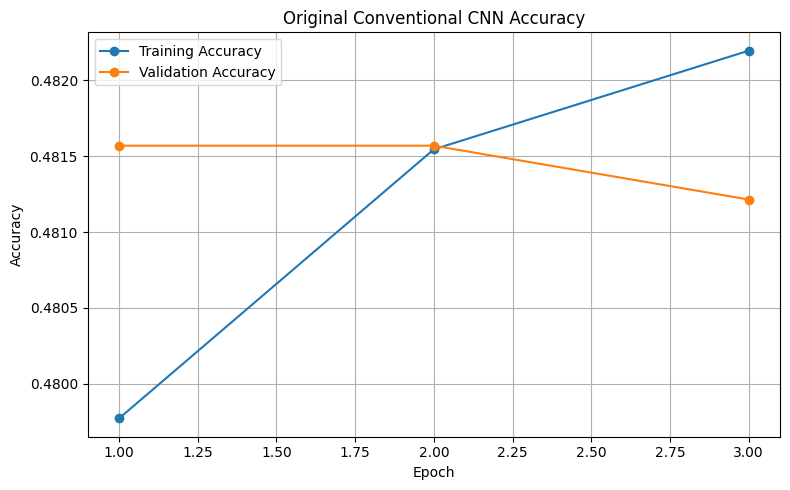

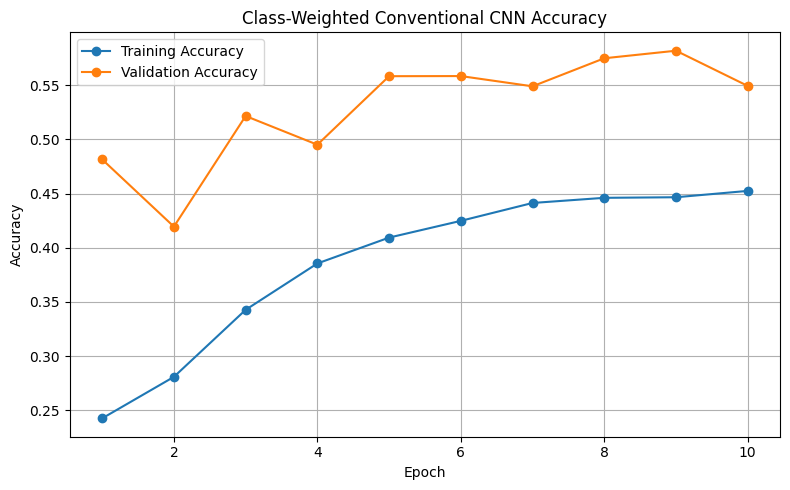

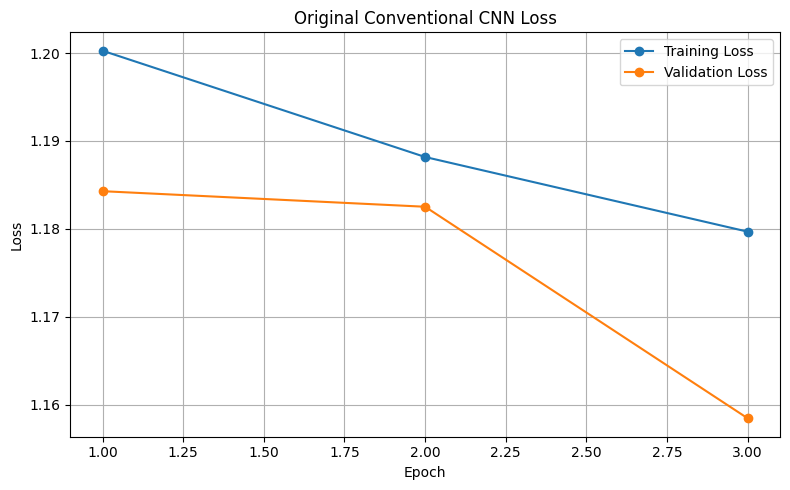

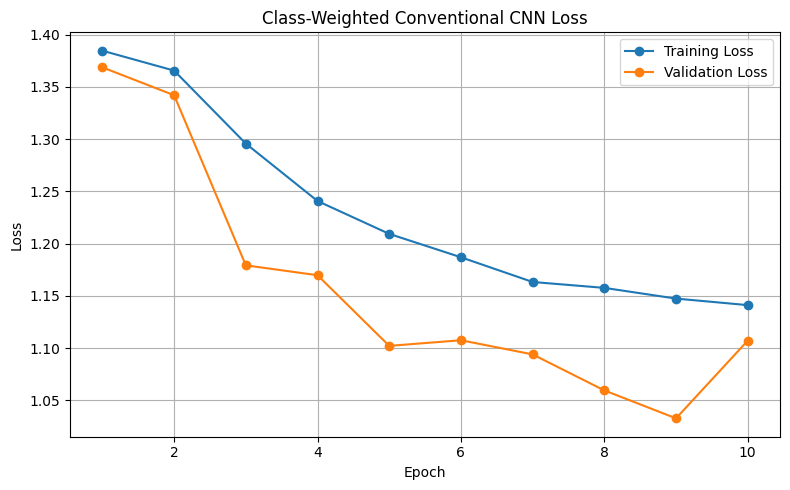

TRAINING HISTORY VISUALISATION COMPLETED

Saved figures:
Original_CNN_Accuracy_Curve.png
Weighted_CNN_Accuracy_Curve.png
Original_CNN_Loss_Curve.png
Weighted_CNN_Loss_Curve.png


In [51]:
# Original CNN Vs class-weighted CNN
# ORIGINAL CNN vs CLASS-WEIGHTED CNN
import matplotlib.pyplot as plt

# original cnn accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    original_history_df["epoch"],
    original_history_df["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    original_history_df["epoch"],
    original_history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Original Conventional CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Original_CNN_Accuracy_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#class-weighted CNN accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    weighted_history_df["epoch"],
    weighted_history_df["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    weighted_history_df["epoch"],
    weighted_history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Class-Weighted Conventional CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Weighted_CNN_Accuracy_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Original cnn loss
plt.figure(figsize=(8, 5))

plt.plot(
    original_history_df["epoch"],
    original_history_df["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    original_history_df["epoch"],
    original_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Original Conventional CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Original_CNN_Loss_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#class-weighted cnn loss
plt.figure(figsize=(8, 5))

plt.plot(
    weighted_history_df["epoch"],
    weighted_history_df["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    weighted_history_df["epoch"],
    weighted_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Class-Weighted Conventional CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Weighted_CNN_Loss_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("============================================================")
print("TRAINING HISTORY VISUALISATION COMPLETED")
print("============================================================")

print("\nSaved figures:")
print("Original_CNN_Accuracy_Curve.png")
print("Weighted_CNN_Accuracy_Curve.png")
print("Original_CNN_Loss_Curve.png")
print("Weighted_CNN_Loss_Curve.png")

FINAL MODEL PERFORMANCE COMPARISON

Loading saved classification reports...
DenseNet121 report loaded.
Conventional CNN report loaded.

EXTRACTING PERFORMANCE METRICS

FINAL MODEL COMPARISON TABLE
             Model  Validation Accuracy  Weighted Precision  Weighted Recall  Weighted F1-Score
  Conventional CNN             0.481569            0.231909         0.481569           0.313058
Class-Weighted CNN             0.581800            0.604100         0.581800           0.581400
       DenseNet121             0.862240            0.861620         0.862240           0.861264

Comparison table saved:
Final_Model_Performance_Comparison.csv

MODEL COMPARISON (%)
             Model  Validation Accuracy  Weighted Precision  Weighted Recall  Weighted F1-Score
  Conventional CNN                48.16               23.19            48.16              31.31
Class-Weighted CNN                58.18               60.41            58.18              58.14
       DenseNet121                86.22      

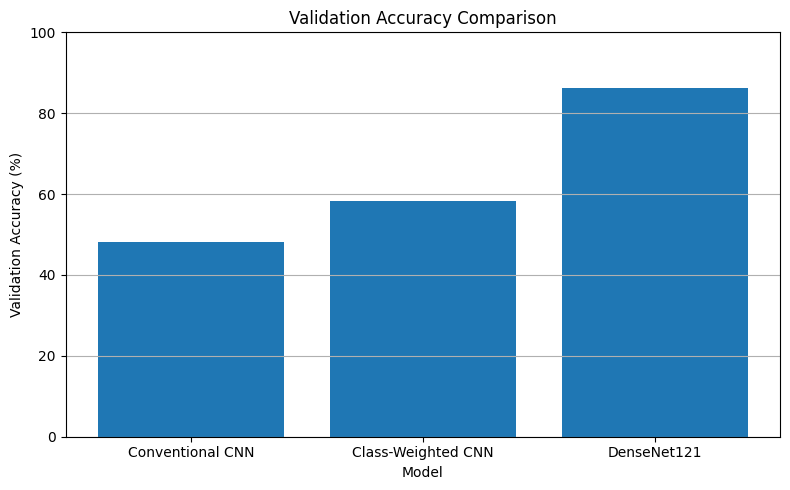

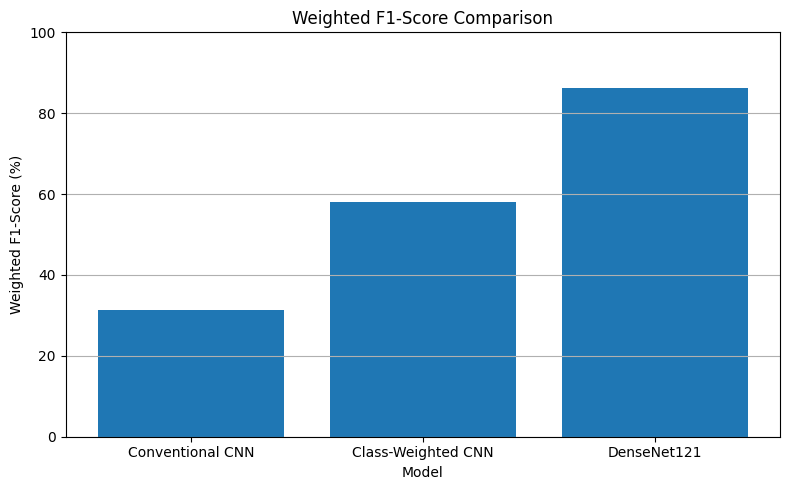


FINAL MODEL COMPARISON COMPLETED


In [52]:
# Final model performance comparision
import os
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

print("============================================================")
print("FINAL MODEL PERFORMANCE COMPARISON")
print("============================================================")

# File paths
densenet_report_path = "DenseNet121_Classification_Report.csv"
cnn_report_path = "Conventional_CNN_Classification_Report.csv"
weighted_report_path = (
    "Conventional_CNN_Weighted_Validation_Classification_Report.txt"
)

# Load classification reports
print("\nLoading saved classification reports...")

# DenseNet121
if os.path.exists(densenet_report_path):

    densenet_report_df = pd.read_csv(
        densenet_report_path,
        index_col=0
    )

    print("DenseNet121 report loaded.")

else:
    raise FileNotFoundError(
        densenet_report_path
    )

# Conventional CNN
if os.path.exists(cnn_report_path):

    cnn_report_df = pd.read_csv(
        cnn_report_path,
        index_col=0
    )

    print("Conventional CNN report loaded.")

else:
    raise FileNotFoundError(
        cnn_report_path
    )

# Weighted cnn
weighted_accuracy = 0.5818
weighted_precision = 0.6041
weighted_recall = 0.5818
weighted_f1 = 0.5814

# Extract matrix
print("\n============================================================")
print("EXTRACTING PERFORMANCE METRICS")
print("============================================================")

# DenseNet121
densenet_accuracy = float(
    densenet_report_df.loc["accuracy", "precision"]
    if "accuracy" in densenet_report_df.index
    else 0.8622
)

densenet_precision = float(
    densenet_report_df.loc[
        "weighted avg",
        "precision"
    ]
)

densenet_recall = float(
    densenet_report_df.loc[
        "weighted avg",
        "recall"
    ]
)

densenet_f1 = float(
    densenet_report_df.loc[
        "weighted avg",
        "f1-score"
    ]
)


# Conventional CNN
cnn_accuracy = float(
    cnn_report_df.loc["accuracy", "precision"]
    if "accuracy" in cnn_report_df.index
    else 0.4816
)

cnn_precision = float(
    cnn_report_df.loc[
        "weighted avg",
        "precision"
    ]
)

cnn_recall = float(
    cnn_report_df.loc[
        "weighted avg",
        "recall"
    ]
)

cnn_f1 = float(
    cnn_report_df.loc[
        "weighted avg",
        "f1-score"
    ]
)


# create comparision table
comparison_df = pd.DataFrame({

    "Model": [
        "Conventional CNN",
        "Class-Weighted CNN",
        "DenseNet121"
    ],

    "Validation Accuracy": [
        cnn_accuracy,
        weighted_accuracy,
        densenet_accuracy
    ],

    "Weighted Precision": [
        cnn_precision,
        weighted_precision,
        densenet_precision
    ],

    "Weighted Recall": [
        cnn_recall,
        weighted_recall,
        densenet_recall
    ],

    "Weighted F1-Score": [
        cnn_f1,
        weighted_f1,
        densenet_f1
    ]
})


print("\n============================================================")
print("FINAL MODEL COMPARISON TABLE")
print("============================================================")

print(
    comparison_df.to_string(
        index=False
    )
)

# save comparision table
comparison_df.to_csv(
    "Final_Model_Performance_Comparison.csv",
    index=False
)

print(
    "\nComparison table saved:"
)

print(
    "Final_Model_Performance_Comparison.csv"
)

# create % vrsion for display
comparison_percentage_df = comparison_df.copy()

metric_columns = [
    "Validation Accuracy",
    "Weighted Precision",
    "Weighted Recall",
    "Weighted F1-Score"
]

for column in metric_columns:

    comparison_percentage_df[column] = (
        comparison_percentage_df[column] * 100
    ).round(2)


print("\n============================================================")
print("MODEL COMPARISON (%)")
print("============================================================")

print(
    comparison_percentage_df.to_string(
        index=False
    )
)

# plot-validation accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_percentage_df["Model"],
    comparison_percentage_df["Validation Accuracy"]
)

plt.title(
    "Validation Accuracy Comparison"
)

plt.xlabel("Model")

plt.ylabel(
    "Validation Accuracy (%)"
)

plt.ylim(
    0,
    100
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.savefig(
    "Final_Model_Validation_Accuracy_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot-weighted F1-score
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_percentage_df["Model"],
    comparison_percentage_df["Weighted F1-Score"]
)

plt.title(
    "Weighted F1-Score Comparison"
)

plt.xlabel("Model")

plt.ylabel(
    "Weighted F1-Score (%)"
)

plt.ylim(
    0,
    100
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.savefig(
    "Final_Model_Weighted_F1_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n============================================================")
print("FINAL MODEL COMPARISON COMPLETED")
print("============================================================")

CONFUSION MATRIX VALIDATION

Original CNN shape: (4, 4)
Class-Weighted CNN shape: (4, 4)
DenseNet121 shape: (4, 4)

All confusion matrices are correctly sized 4 × 4.

Generating Original CNN confusion matrix...


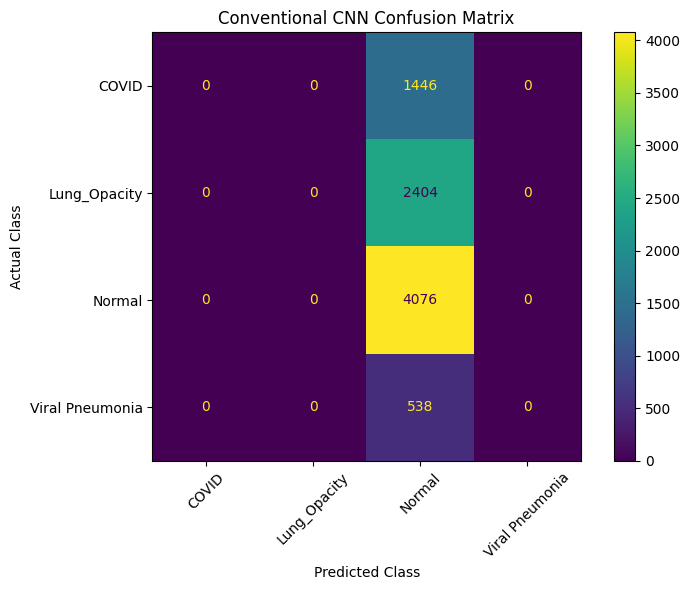

Generating Class-Weighted CNN confusion matrix...


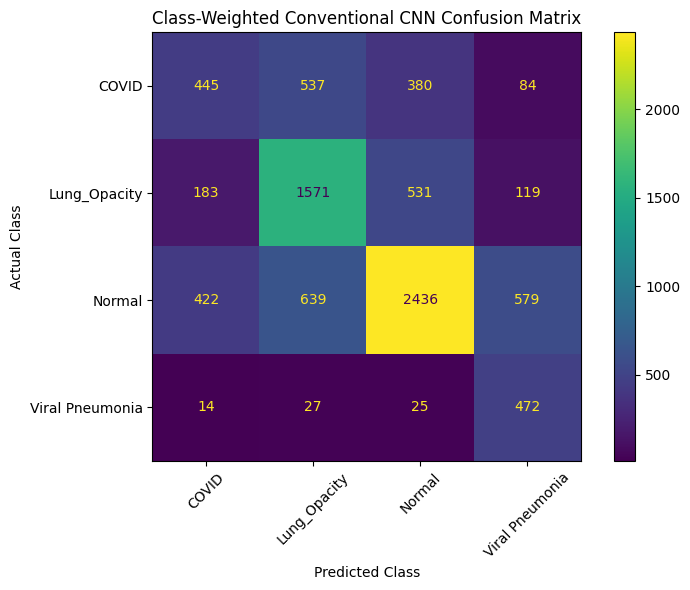

Generating DenseNet121 confusion matrix...


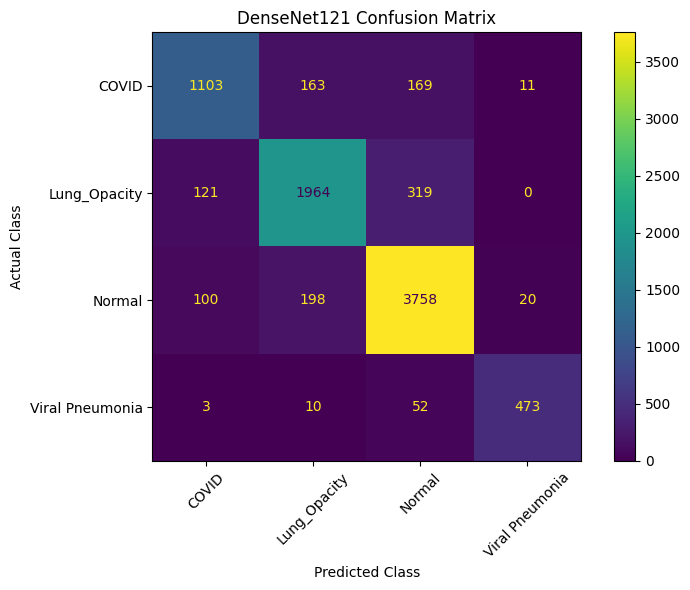


CONFUSION MATRIX VISUALISATION COMPLETED

Saved figures:
1. Original_CNN_Confusion_Matrix.png
2. Weighted_CNN_Confusion_Matrix.png
3. DenseNet121_Confusion_Matrix.png


In [55]:
# Final confusion matrix visualisation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# class names
class_labels = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

# Original CNN
cnn_cm = np.array([
    [0,    0, 1446, 0],
    [0,    0, 2404, 0],
    [0,    0, 4076, 0],
    [0,    0,  538, 0]
])


# Class weighted CNN
weighted_cnn_cm = np.array([
    [445, 537, 380,  84],
    [183, 1571, 531, 119],
    [422, 639, 2436, 579],
    [ 14,  27,  25, 472]
])


# DenseNet121
densenet_cm = np.array([
    [1103, 163, 169,  11],
    [ 121, 1964, 319,   0],
    [ 100,  198, 3758, 20],
    [   3,  10,  52, 473]
])


# chect matrix
print("================================")
print("CONFUSION MATRIX VALIDATION")
print("================================")

print("\nOriginal CNN shape:", cnn_cm.shape)
print("Class-Weighted CNN shape:", weighted_cnn_cm.shape)
print("DenseNet121 shape:", densenet_cm.shape)

assert cnn_cm.shape == (4, 4)
assert weighted_cnn_cm.shape == (4, 4)
assert densenet_cm.shape == (4, 4)

print("\nAll confusion matrices are correctly sized 4 × 4.")

# plotting function
def plot_confusion_matrix(cm, title, filename):

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(
        ax=ax,
        values_format="d",
        xticks_rotation=45
    )

    ax.set_title(title)

    ax.set_xlabel(
        "Predicted Class"
    )

    ax.set_ylabel(
        "Actual Class"
    )

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# original CNN
print("\nGenerating Original CNN confusion matrix...")

plot_confusion_matrix(
    cnn_cm,
    "Conventional CNN Confusion Matrix",
    "Original_CNN_Confusion_Matrix.png"
)

# class weighted CNN
print("Generating Class-Weighted CNN confusion matrix...")

plot_confusion_matrix(
    weighted_cnn_cm,
    "Class-Weighted Conventional CNN Confusion Matrix",
    "Weighted_CNN_Confusion_Matrix.png"
)

# DenseNet121
print("Generating DenseNet121 confusion matrix...")

plot_confusion_matrix(
    densenet_cm,
    "DenseNet121 Confusion Matrix",
    "DenseNet121_Confusion_Matrix.png"
)

# Completed
print("\n========================================")
print("CONFUSION MATRIX VISUALISATION COMPLETED")
print("==========================================")

print("\nSaved figures:")
print("1. Original_CNN_Confusion_Matrix.png")
print("2. Weighted_CNN_Confusion_Matrix.png")
print("3. DenseNet121_Confusion_Matrix.png")

In [56]:
# DenseNet121 Grad-CAM setup check
import os
import tensorflow as tf
from tensorflow.keras.models import load_model

print("================================")
print("DENSENET121 GRAD-CAM SETUP CHECK")
print("================================")

model_path = "DenseNet121_ChestXray_Model.h5"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"DenseNet121 model not found: {model_path}"
    )

# Load saved DenseNet121
densenet_model = load_model(model_path)

print("\nDenseNet121 loaded successfully.")

print(
    "Total parameters:",
    densenet_model.count_params()
)

print(
    "Input shape:",
    densenet_model.input_shape
)

print(
    "Output shape:",
    densenet_model.output_shape
)

# Find convolutional layers
print("\n===================")
print("CONVOLUTIONAL LAYERS")
print("=====================")

conv_layers = []

for layer in densenet_model.layers:

    if len(layer.output.shape) == 4:

        conv_layers.append(
            layer
        )

print(
    "Number of 4D feature-map layers:",
    len(conv_layers)
)

print("\nLast 10 suitable layers:")

for layer in conv_layers[-10:]:

    print(
        layer.name,
        "->",
        layer.output.shape
    )


# Selected grad-cam layer
gradcam_layer = conv_layers[-1]

print("\n======================")
print("SELECTED GRAD-CAM LAYER")
print("========================")

print(
    "Layer name:",
    gradcam_layer.name
)

print(
    "Layer output:",
    gradcam_layer.output.shape
)

print("\nGrad-CAM setup check completed.")

DENSENET121 GRAD-CAM SETUP CHECK

DenseNet121 loaded successfully.
Total parameters: 7564356
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)

CONVOLUTIONAL LAYERS
Number of 4D feature-map layers: 427

Last 10 suitable layers:
conv5_block15_concat -> (None, 7, 7, 992)
conv5_block16_0_bn -> (None, 7, 7, 992)
conv5_block16_0_relu -> (None, 7, 7, 992)
conv5_block16_1_conv -> (None, 7, 7, 128)
conv5_block16_1_bn -> (None, 7, 7, 128)
conv5_block16_1_relu -> (None, 7, 7, 128)
conv5_block16_2_conv -> (None, 7, 7, 32)
conv5_block16_concat -> (None, 7, 7, 1024)
bn -> (None, 7, 7, 1024)
relu -> (None, 7, 7, 1024)

SELECTED GRAD-CAM LAYER
Layer name: relu
Layer output: (None, 7, 7, 1024)

Grad-CAM setup check completed.


In [57]:
# reusable DeseNet121 Grad-CAM function
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image

# class names
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

# Grad-CAM functions
def generate_gradcam(
    model,
    image_path,
    gradcam_layer_name="relu",
    image_size=(224, 224)
):
    """
    Generate DenseNet121 prediction and Grad-CAM explanation.

    Returns:
        original_image
        predicted_class
        predicted_class_index
        confidence
        probabilities
        heatmap
        overlay
    """

    # check image
    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Load image
    img = image.load_img(
        image_path,
        target_size=image_size
    )

    img_array = image.img_to_array(
        img
    )

    original_image = img_array.astype(
        np.uint8
    )

    # preprocess image
    input_array = np.expand_dims(
        img_array,
        axis=0
    )

    input_array = input_array / 255.0

    input_tensor = tf.convert_to_tensor(
        input_array,
        dtype=tf.float32
    )

    # create Grad-CAM model
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(
                gradcam_layer_name
            ).output,
            model.output
        ]
    )

    # forward pass plus gradient
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            input_tensor
        )

        predicted_class_index = tf.argmax(
            predictions[0]
        )

        class_score = predictions[
            0,
            predicted_class_index
        ]

    #claculate gradients
    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # global average pooling
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # remove batch dimensions
    conv_outputs = conv_outputs[0]

    pooled_gradients = pooled_gradients[0]

    # weight feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalise
    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:

        heatmap = (
            heatmap /
            max_value
        )

    heatmap = heatmap.numpy()

    # Resize heatmap
    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        image_size
    )

    heatmap = heatmap.numpy().squeeze()

    #model probabilities
    probabilities = predictions[
        0
    ].numpy()

    predicted_class_index = int(
        predicted_class_index.numpy()
    )

    predicted_class = class_names[
        predicted_class_index
    ]

    confidence = float(
        probabilities[
            predicted_class_index
        ]
    )

    # create visual overlay
    colormap = plt.get_cmap(
        "jet"
    )

    colored_heatmap = colormap(
        heatmap
    )[:, :, :3]

    colored_heatmap = (
        colored_heatmap * 255
    ).astype(
        np.uint8
    )

    # Convert original image to float
    original_float = (
        original_image.astype(
            np.float32
        )
    )

    heatmap_float = (
        colored_heatmap.astype(
            np.float32
        )
    )

    # Blend original image + heatmap
    overlay = (
        0.6 * original_float
        +
        0.4 * heatmap_float
    )

    overlay = np.clip(
        overlay,
        0,
        255
    ).astype(
        np.uint8
    )

    # return results
    return {
        "original_image": original_image,
        "predicted_class": predicted_class,
        "predicted_class_index": predicted_class_index,
        "confidence": confidence,
        "probabilities": probabilities,
        "heatmap": heatmap,
        "overlay": overlay
    }

print("====================================")
print("REUSABLE GRAD-CAM FUNCTION CREATED")
print("=====================================")

REUSABLE GRAD-CAM FUNCTION CREATED


In [58]:
import os

print(os.path.exists(
    r"COVID-1.png"
))

False


In [59]:
import os

matches = []

for root, dirs, files in os.walk(
    r"C:\Users\97150\Documents"
):

    for file in files:

        if file.lower() == "covid-1.png":

            matches.append(
                os.path.join(
                    root,
                    file
                )
            )

print("Found images:")

for path in matches:
    print(path)

Found images:


TESTING GRAD-CAM
Image path: 
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png

Image exists: True

DENSENET121 PREDICTION
Predicted class: COVID
Confidence: 98.11%

CLASS PROBABILITIES
COVID: 98.11%
Lung_Opacity: 1.87%
Normal: 0.02%
Viral Pneumonia: 0.00%


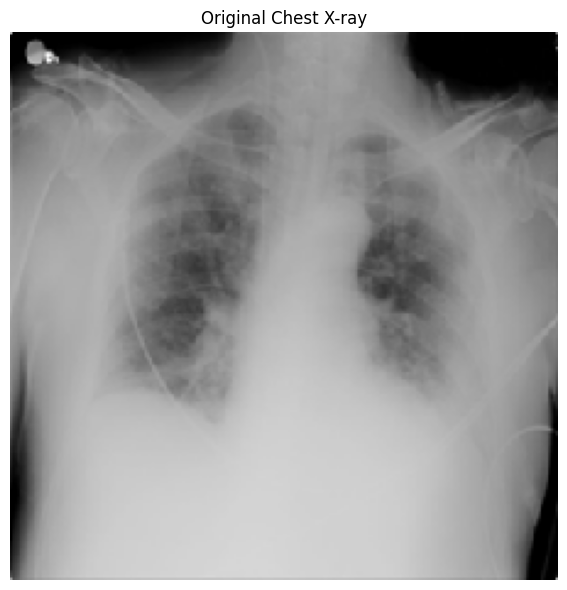

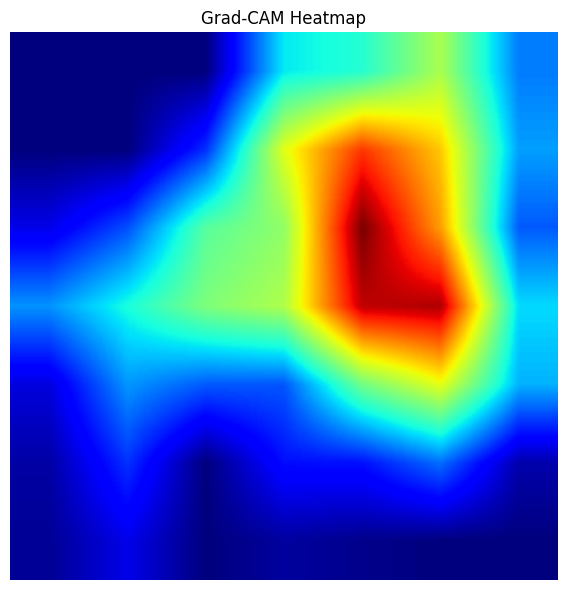

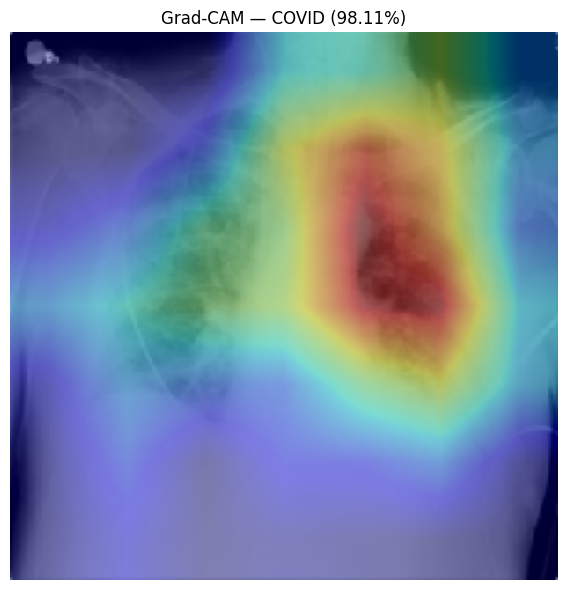

GRAD-CAM TEST COMPLETED


In [60]:
# testing Grad-CAM on one x-ray image

image_path = r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png"

print("TESTING GRAD-CAM")

print("Image path: ")
print(image_path)

print(
    "\nImage exists:",
    os.path.exists(image_path)
)

if not os.path.exists(image_path):
    raise FileNotFoundError(
        "The specified X-ray image could not be found."
    )

#Generate Gard-CAM
gradcam_result = generate_gradcam(
    model=densenet_model,
    image_path=image_path,
    gradcam_layer_name="relu",
    image_size=(224, 224)
)

# Display prediction info
print("\n=============================")
print("DENSENET121 PREDICTION")
print("===============================")

print(
    "Predicted class:",
    gradcam_result["predicted_class"]
)

print(
    f"Confidence: "
    f"{gradcam_result['confidence'] * 100:.2f}%"
)


#Display all class probabilities
print("\n==================")
print("CLASS PROBABILITIES")
print("====================")

for class_name, probability in zip(
    class_names,
    gradcam_result["probabilities"]
):

    print(
        f"{class_name}: "
        f"{probability * 100:.2f}%"
    )


# Display original image
plt.figure(figsize=(6, 6))

plt.imshow(
    gradcam_result["original_image"]
)

plt.title(
    "Original Chest X-ray"
)

plt.axis("off")

plt.tight_layout()

plt.show()

# Display Grad-CAM heatmap
plt.figure(figsize=(6, 6))

plt.imshow(
    gradcam_result["heatmap"],
    cmap="jet"
)

plt.title(
    "Grad-CAM Heatmap"
)

plt.axis("off")

plt.tight_layout()

plt.show()

# Display overlay
plt.figure(figsize=(6, 6))

plt.imshow(
    gradcam_result["overlay"]
)

plt.title(
    f"Grad-CAM — {gradcam_result['predicted_class']} "
    f"({gradcam_result['confidence'] * 100:.2f}%)"
)

plt.axis("off")

plt.tight_layout()

plt.show()

print("GRAD-CAM TEST COMPLETED")

In [63]:
# finding the datasset root used by validation generator
print("CHECKING VALIDATION GENERATOR DIRECTORY")

try:
    print("\nValidation generator directory:")
    print(validation_generator.directory)

except Exception as e:
    print("\nCould not read validation_generator.directory")
    print("Error:", e)

CHECKING VALIDATION GENERATOR DIRECTORY

Validation generator directory:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset


In [64]:
# finding represetative image from each class
# STEP 5D — FIND REPRESENTATIVE IMAGE FROM EACH CLASS

import os

dataset_directory = (
    r"C:\Users\97150\OneDrive\Desktop\Project"
    r"\covid-19 dataset\COVID-19_Radiography_Dataset"
)

print("SEARCHING DATASET FOR REPRESENTATIVE X-RAY IMAGES")

print("\nDataset directory:")
print(dataset_directory)

# Classes used in the project
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

valid_extensions = (".png", ".jpg", ".jpeg")

found_images = {}

for class_name in class_names:

    found_images[class_name] = None

    for root, dirs, files in os.walk(dataset_directory):

        # Only search inside folders belonging to this class
        if class_name.lower() in root.lower():

            image_files = [
                file for file in files
                if file.lower().endswith(valid_extensions)
            ]

            if len(image_files) > 0:

                found_images[class_name] = os.path.join(
                    root,
                    image_files[0]
                )

                break

print("REPRESENTATIVE IMAGES FOUND")

for class_name, image_path in found_images.items():

    if image_path is not None:
        print(f"\n{class_name}:")
        print(image_path)

    else:
        print(f"\n{class_name}: NOT FOUND")

SEARCHING DATASET FOR REPRESENTATIVE X-RAY IMAGES

Dataset directory:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset
REPRESENTATIVE IMAGES FOUND

COVID:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png

Lung_Opacity:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-1.png

Normal:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Normal\images\Normal-1.png

Viral Pneumonia:
C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Viral Pneumonia\images\Viral Pneumonia-1.png


In [67]:
import inspect

print(inspect.signature(generate_gradcam))

(model, image_path, gradcam_layer_name='relu', image_size=(224, 224))


GENERATING GRAD-CAM RESULTS

Output directory:
C:\Users\97150\Documents\GradCAM_Final_Results

------------------------------------------------------------
Processing: COVID
Image: C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png
Actual class    : COVID
Predicted class : COVID
Class index     : 0
Confidence      : 98.11%


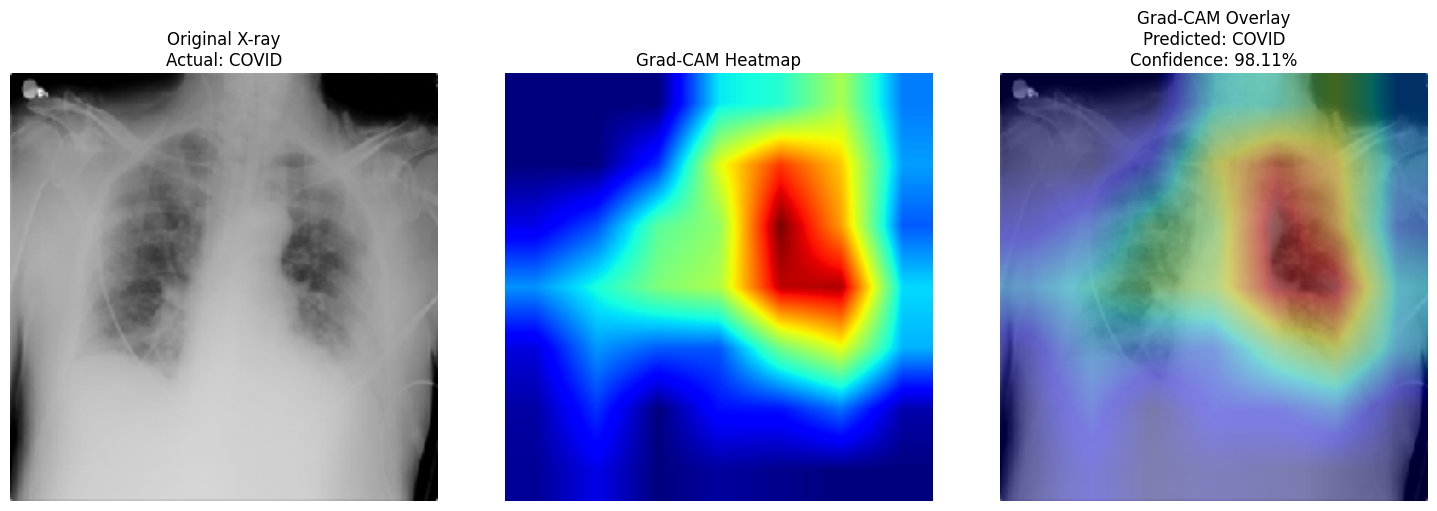

Saved: C:\Users\97150\Documents\GradCAM_Final_Results\GradCAM_Final_COVID.png

------------------------------------------------------------
Processing: Lung_Opacity
Image: C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-1.png
Actual class    : Lung_Opacity
Predicted class : Lung_Opacity
Class index     : 1
Confidence      : 59.55%


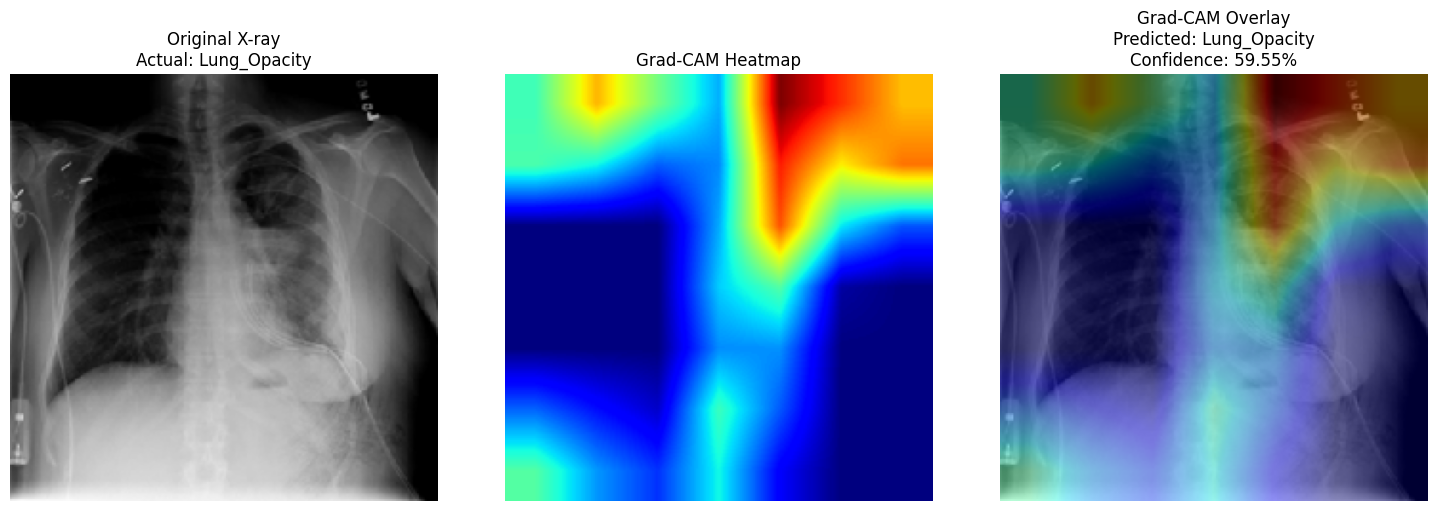

Saved: C:\Users\97150\Documents\GradCAM_Final_Results\GradCAM_Final_Lung_Opacity.png

------------------------------------------------------------
Processing: Normal
Image: C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Normal\images\Normal-1.png
Actual class    : Normal
Predicted class : Normal
Class index     : 2
Confidence      : 91.17%


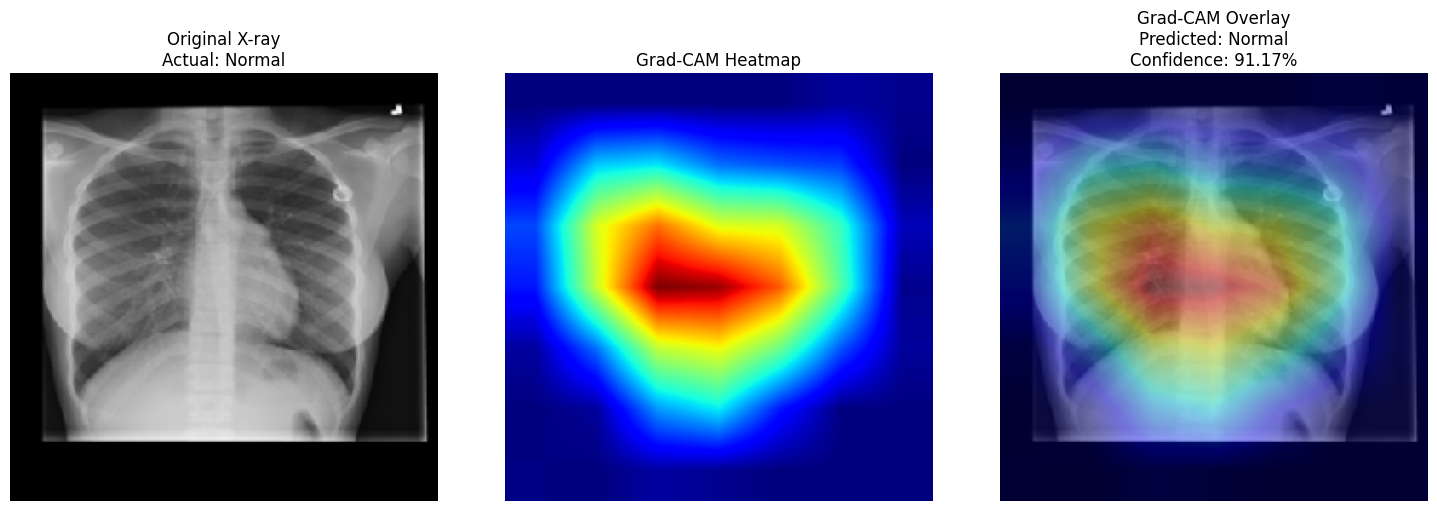

Saved: C:\Users\97150\Documents\GradCAM_Final_Results\GradCAM_Final_Normal.png

------------------------------------------------------------
Processing: Viral Pneumonia
Image: C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Viral Pneumonia\images\Viral Pneumonia-1.png
Actual class    : Viral Pneumonia
Predicted class : Viral Pneumonia
Class index     : 3
Confidence      : 99.87%


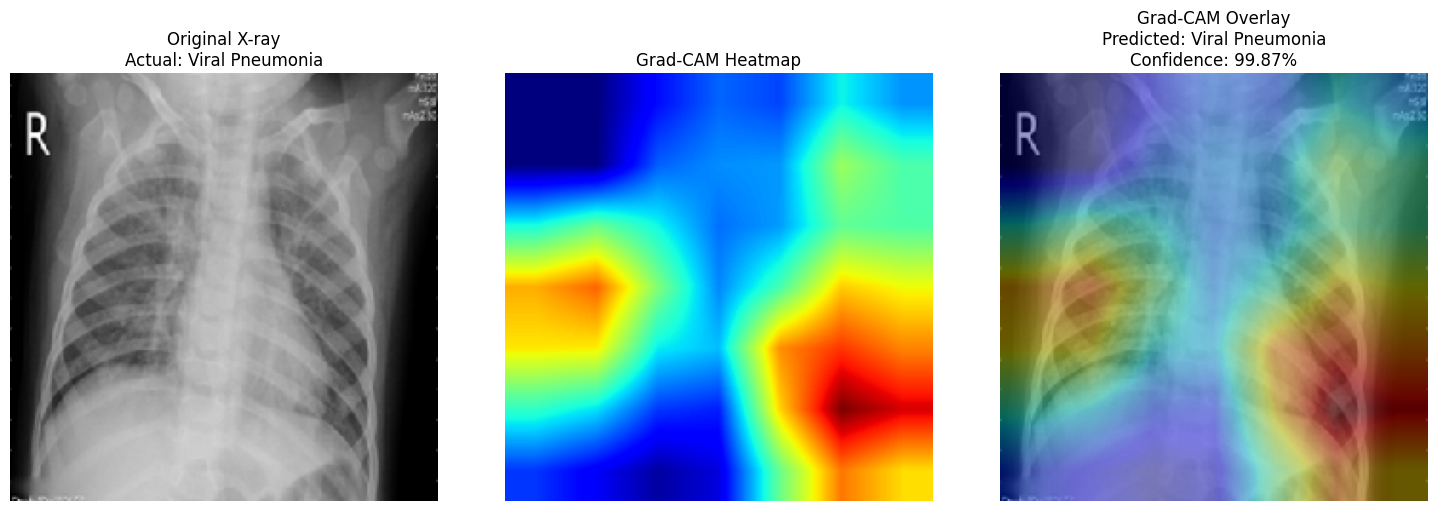

Saved: C:\Users\97150\Documents\GradCAM_Final_Results\GradCAM_Final_Viral_Pneumonia.png
GRAD-CAM GENERATION COMPLETED


,Actual Class,Predicted Class,Predicted Class Index,Confidence,Probability_COVID,Probability_Lung_Opacity,Probability_Normal,Probability_Viral Pneumonia
0,COVID,COVID,0,0.981121,0.981121,0.018659,0.000201,0.000020
1,Lung_Opacity,Lung_Opacity,1,0.595510,0.120916,0.595510,0.283384,0.000190
2,Normal,Normal,2,0.911712,0.053216,0.035040,0.911712,0.000032
3,Viral Pneumonia,Viral Pneumonia,3,0.998657,0.000546,0.000316,0.000481,0.998657



Summary CSV saved to:
C:\Users\97150\Documents\GradCAM_Final_Results\GradCAM_Final_Summary.csv


In [70]:
# Generate final Grad-CAM results
import os
import pandas as pd
import matplotlib.pyplot as plt

print("GENERATING GRAD-CAM RESULTS")

# Representative images
representative_images = {
    "COVID": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png",

    "Lung_Opacity": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-1.png",

    "Normal": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Normal\images\Normal-1.png",

    "Viral Pneumonia": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Viral Pneumonia\images\Viral Pneumonia-1.png"
}

# Output directory
output_directory = r"C:\Users\97150\Documents\GradCAM_Final_Results"

os.makedirs(
    output_directory,
    exist_ok=True
)

print("\nOutput directory:")
print(output_directory)

# Generate Grad-CAM
results = []

for true_class, image_path in representative_images.items():

    print("\n------------------------------------------------------------")
    print("Processing:", true_class)
    print("Image:", image_path)

    # Check image exists
    if not os.path.exists(image_path):

        print("ERROR: Image not found.")
        continue
        
    # Generate Grad-CAM
    gradcam_result = generate_gradcam(
        densenet_model,
        image_path,
        gradcam_layer_name="relu"
    )

    # Extract results from dictionary
    original_img = gradcam_result[
        "original_image"
    ]

    predicted_class = gradcam_result[
        "predicted_class"
    ]

    predicted_class_index = gradcam_result[
        "predicted_class_index"
    ]

    confidence = gradcam_result[
        "confidence"
    ]

    probabilities = gradcam_result[
        "probabilities"
    ]

    heatmap = gradcam_result[
        "heatmap"
    ]

    overlay = gradcam_result[
        "overlay"
    ]
    
    # Print prediction information
    print("Actual class    :", true_class)
    print("Predicted class :", predicted_class)
    print("Class index     :", predicted_class_index)
    print("Confidence      :", f"{confidence * 100:.2f}%")

    # Create three-panel figure
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    # Original X-ray
    axes[0].imshow(
        original_img,
        cmap="gray"
    )

    axes[0].set_title(
        f"Original X-ray\nActual: {true_class}"
    )

    axes[0].axis("off")

    # Grad-CAM heatmap
    axes[1].imshow(
        heatmap,
        cmap="jet"
    )

    axes[1].set_title(
        "Grad-CAM Heatmap"
    )

    axes[1].axis("off")

    # Grad-CAM overlay
    axes[2].imshow(
        overlay
    )

    axes[2].set_title(
        f"Grad-CAM Overlay\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    axes[2].axis("off")

    plt.tight_layout()

    # Save figure
    safe_name = true_class.replace(
        " ",
        "_"
    )

    output_path = os.path.join(
        output_directory,
        f"GradCAM_Final_{safe_name}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("Saved:", output_path)

    # Store results
    result_row = {
        "Actual Class": true_class,
        "Predicted Class": predicted_class,
        "Predicted Class Index": predicted_class_index,
        "Confidence": confidence
    }

    for class_name, probability in zip(
        class_names,
        probabilities
    ):

        result_row[
            f"Probability_{class_name}"
        ] = probability

    results.append(
        result_row
    )

# Create summary DataFrame
results_df = pd.DataFrame(
    results
)

# Save summary CSV
csv_path = os.path.join(
    output_directory,
    "GradCAM_Final_Summary.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

# Display final summary

print("GRAD-CAM GENERATION COMPLETED")

display(
    results_df
)

print("\nSummary CSV saved to:")
print(csv_path)

In [72]:
# Instal Open AI
%pip install -U openai


  Obtaining dependency information for anyio<5,>=4.10.0 from https://files.pythonhosted.org/packages/12/b8/4bd346e22b28902df4d651910f5242c28d84e4a5c2435ca5c3f797ed7e2e/anyio-4.15.1-py3-none-any.whl.metadata
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
Using cached anyio-4.15.1-py3-none-any.whl (132 kB)
  Attempting uninstall: anyio
    Found existing installation: anyio 3.5.0
    Uninstalling anyio-3.5.0:
      Successfully uninstalled anyio-3.5.0


In [76]:
%pip install --upgrade "typing_extensions>=4.15.0"

Note: you may need to restart the kernel to use updated packages.


In [1]:
import typing_extensions

print("Location:")
print(typing_extensions.__file__)

print("\nSentinel available:")
print(hasattr(typing_extensions, "Sentinel"))

print("\nVersion:")
try:
    from importlib.metadata import version
    print(version("typing_extensions"))
except Exception as e:
    print("Could not read version:", e)

Location:
C:\Users\97150\anaconda3\Lib\site-packages\typing_extensions.py

Sentinel available:
True

Version:
4.16.0


In [4]:
%pip install --upgrade "aiohttp>=3.14.1"

  Obtaining dependency information for aiohttp>=3.14.1 from https://files.pythonhosted.org/packages/73/0c/2af9d1674baccd1dbd47282a93d660a22e57ef6167c856deb24b4214fbab/aiohttp-3.14.3-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for aiohappyeyeballs>=2.5.0 from https://files.pythonhosted.org/packages/71/43/1947f06babed6b3f1d7f38b0c767f52df66bfb2bc10b468c4a7de9eceff2/aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata
  Obtaining dependency information for aiosignal>=1.4.0 from https://files.pythonhosted.org/packages/fb/76/641ae371508676492379f16e2fa48f4e2c11741bd63c48be4b12a6b09cba/aiosignal-1.4.0-py3-none-any.whl.metadata
  Obtaining dependency information for propcache>=0.2.0 from https://files.pythonhosted.org/packages/42/4e/f17363fb58c0afe05b067361cb6d86ed2d29de6506779a27547c4d183075/propcache-0.5.2-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for yarl<2.0,>=1.17.0 from https://files.pythonhosted.org/packages/f5/46/d7bd3a8859d47dcfaffd71

In [1]:
import aiohttp

print("aiohttp version:")
print(aiohttp.__version__)

print("\nSocketTimeoutError available:")
print(hasattr(aiohttp, "SocketTimeoutError"))

aiohttp version:
3.14.3

SocketTimeoutError available:
True


In [7]:
%pip install "h11>=0.16"

  Obtaining dependency information for h11>=0.16 from https://files.pythonhosted.org/packages/04/4b/29cac41a4d98d144bf5f6d33995617b185d14b22401f75ca86f384e87ff1/h11-0.16.0-py3-none-any.whl.metadata
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
  Attempting uninstall: h11
    Found existing installation: h11 0.14.0
    Uninstalling h11-0.14.0:
      Successfully uninstalled h11-0.14.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
httpcore 1.0.6 requires h11<0.15,>=0.13, but you have h11 0.16.0 which is incompatible.


In [8]:
%pip install ollama

  Obtaining dependency information for h11<0.15,>=0.13 from https://files.pythonhosted.org/packages/95/04/ff642e65ad6b90db43e668d70ffb6736436c7ce41fcc549f4e9472234127/h11-0.14.0-py3-none-any.whl.metadata
  Using cached h11-0.14.0-py3-none-any.whl.metadata (8.2 kB)
Using cached h11-0.14.0-py3-none-any.whl (58 kB)
  Attempting uninstall: h11
    Found existing installation: h11 0.16.0
    Uninstalling h11-0.16.0:
      Successfully uninstalled h11-0.16.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
httpcore2 2.12.0 requires h11>=0.16, but you have h11 0.14.0 which is incompatible.


In [1]:
import ollama
print("Ollama Python library imported successfully")

Ollama Python library imported successfully


In [3]:
import h11
import httpcore

print("h11 version:", h11.__version__)
print("httpcore version:", httpcore.__version__)

h11 version: 0.14.0
httpcore version: 1.0.6


In [4]:
import requests

response = requests.post(
    "http://localhost:11434/api/generate",
    json={
        "model": "gemma3:4b",
        "prompt": "Respond with exactly: LLM connection successful.", 
        "Stream": False
    },
    timeout=120
)
print("Status code:", response.status_code)
print("LLM response:")
print(response.json()["response"])

Status code: 200
LLM response:
LLM connection successful.



In [6]:
import os
import glob

print("Current notebook folder:")
print(os.getcwd())

print("\nSearching for DenseNet121 model...")

model_files = glob.glob(
    os.path.join(os.getcwd(), "**", "DenseNet121_ChestXray_Model.h5"),
    recursive=True
)

if model_files:
    for path in model_files:
        print("FOUND:", path)
else:
    print("Model not found in the current notebook folder.")

Current notebook folder:
C:\Users\97150\Documents

Searching for DenseNet121 model...
FOUND: C:\Users\97150\Documents\DenseNet121_ChestXray_Model.h5


In [7]:
import tensorflow as tf
from tensorflow.keras.models import load_model

model_path = r"C:\Users\97150\Documents\DenseNet121_ChestXray_Model.h5"

print("Loading DenseNet121 model...")

model = load_model(model_path)

print("DenseNet121 model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())


Loading DenseNet121 model...


DenseNet121 model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Total parameters: 7564356


In [8]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# Grad-CAM function
def generate_gradcam(
    model,
    image_path,
    gradcam_layer_name="relu",
    image_size=(224, 224)
):
    """
    Generate Grad-CAM explanation for a chest X-ray image.

    Returns:
        Dictionary containing:
        - original_image
        - predicted_class
        - predicted_class_index
        - confidence
        - probabilities
        - heatmap
        - overlay
    """

    # Class names used by the DenseNet121 model
    class_names = [
        "COVID",
        "Lung_Opacity",
        "Normal",
        "Viral Pneumonia"
    ]

    # Load and preprocess image
    original_image = Image.open(image_path).convert("RGB")
    original_image = original_image.resize(image_size)

    image_array = np.array(original_image).astype("float32") / 255.0
    input_image = np.expand_dims(image_array, axis=0)

    # Create Grad-CAM model
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(gradcam_layer_name).output,
            model.output
        ]
    )

    # Calculate Grad-CAM
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(input_image)

        predicted_class_index = tf.argmax(
            predictions[0]
        )

        class_score = predictions[:, predicted_class_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients over spatial dimensions
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    # Weight feature maps by gradients
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(heatmap, 0)

    # Normalize
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    heatmap = heatmap.numpy()

    # Resize heatmap
    heatmap_image = Image.fromarray(
        np.uint8(heatmap * 255)
    )

    heatmap_image = heatmap_image.resize(
        image_size,
        Image.Resampling.BILINEAR
    )

    heatmap = np.array(heatmap_image).astype("float32") / 255.0

    # Create coloured heatmap
    cmap = plt.get_cmap("jet")

    colored_heatmap = cmap(heatmap)[:, :, :3]

    # Create overlay
    overlay = (
        0.6 * image_array +
        0.4 * colored_heatmap
    )

    overlay = np.clip(
        overlay,
        0,
        1
    )

    # Prediction information
    probabilities = predictions[0].numpy()

    predicted_class_index = int(
        predicted_class_index.numpy()
    )

    predicted_class = class_names[
        predicted_class_index
    ]

    confidence = float(
        probabilities[predicted_class_index]
    )

    # Return results
    return {
        "original_image": image_array,
        "predicted_class": predicted_class,
        "predicted_class_index": predicted_class_index,
        "confidence": confidence,
        "probabilities": probabilities,
        "heatmap": heatmap,
        "overlay": overlay
    }


print("Grad-CAM function restored successfully.")

Grad-CAM function restored successfully.


In [9]:
layer = model.get_layer("relu")

print("Grad-CAM layer found successfully.")
print("Layer name:", layer.name)
print("Layer output shape:", layer.output.shape)

Grad-CAM layer found successfully.
Layer name: relu
Layer output shape: (None, 7, 7, 1024)


In [10]:
covid_image_path = r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png"

result = generate_gradcam(
    model,
    covid_image_path,
    gradcam_layer_name="relu"
)

print("Predicted class:", result["predicted_class"])
print("Confidence:", f"{result['confidence']:.2%}")

print("\nClass probabilities:")

class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

for class_name, probability in zip(
    class_names,
    result["probabilities"]
):
    print(f"{class_name}: {probability:.2%}")

Predicted class: COVID
Confidence: 97.82%

Class probabilities:
COVID: 97.82%
Lung_Opacity: 2.15%
Normal: 0.03%
Viral Pneumonia: 0.00%


In [11]:
#Create LLM report function
import requests

def generate_llm_report(result):
    """
    Generate a structured AI-assisted report using
    the local Gemma 3 4B model.

    The LLM receives only the classification results
    produced by DenseNet121 and information that
    Grad-CAM was generated.
    """

    class_names = [
        "COVID",
        "Lung_Opacity",
        "Normal",
        "Viral Pneumonia"
    ]

    predicted_class = result["predicted_class"]
    confidence = result["confidence"]
    probabilities = result["probabilities"]

    probability_text = "\n".join(
        f"- {class_name}: {probability:.2%}"
        for class_name, probability in zip(
            class_names,
            probabilities
        )
    )

    prompt = f"""
You are the language-generation component of a university
research prototype called an Explainable AI-Powered
Intelligent Radiology Assistant.

A DenseNet121 deep learning model has classified a chest
X-ray image.

The model produced the following results:

Predicted class:
{predicted_class}

Prediction confidence:
{confidence:.2%}

Class probability distribution:
{probability_text}

A Grad-CAM explainability visualization has also been
generated for this prediction.

Generate a concise, structured AI-assisted report using
ONLY the information provided above.

Use the following sections:

1. AI Prediction
2. Confidence
3. Probability Distribution
4. Explainability
5. Interpretation
6. Important Disclaimer

IMPORTANT RULES:

- Do NOT invent anatomical findings.
- Do NOT describe specific abnormalities visible in the
  X-ray because no such findings have been provided.
- Do NOT claim that you personally examined the X-ray.
- Do NOT provide treatment or medical advice.
- Do NOT present the AI prediction as a confirmed diagnosis.
- Clearly state that the result is produced by a research
  prototype.
- Explain that Grad-CAM provides a visual indication of
  image regions that contributed to the model prediction.
- Keep the report professional and concise.
"""

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "gemma3:4b",
            "prompt": prompt,
            "stream": False
        },
        timeout=180
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"Ollama request failed: "
            f"{response.status_code}\n"
            f"{response.text}"
        )

    return response.json()["response"]

In [12]:
report = generate_llm_report(result)
print(report)

## AI-Assisted Radiology Report – Research Prototype

**1. AI Prediction:**

The DenseNet121 model has predicted the presence of COVID.

**2. Confidence:**

The model’s prediction has a confidence level of 97.82%.

**3. Probability Distribution:**

The predicted probabilities for the classes are as follows:

*   COVID: 97.82%
*   Lung Opacity: 2.15%
*   Normal: 0.03%
*   Viral Pneumonia: 0.00%

**4. Explainability:**

A Grad-CAM visualization has been generated, providing a visual indication of the regions within the chest X-ray image that the model deemed most relevant to its prediction. 

**5. Interpretation:**

Based on the model’s prediction and associated probabilities, the research prototype suggests a potential association with COVID-19. Further investigation and clinical correlation are required.

**6. Important Disclaimer:**

This report is generated by a research prototype, an Explainable AI-Powered Intelligent Radiology Assistant. The model’s output represents a preliminary 

In [13]:
import requests

CLASS_NAMES = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]


def generate_llm_report(result):
    """
    Generate a structured AI-assisted chest X-ray
    classification report using the local Gemma 3 4B model.

    DenseNet121:
        Performs image classification.

    Grad-CAM:
        Provides the explainability visualization.

    Gemma 3:
        Converts the model outputs into a structured
        natural-language report.
    """

    predicted_class = result["predicted_class"]
    confidence = result["confidence"]
    probabilities = result["probabilities"]

    probability_text = "\n".join(
        f"{class_name}: {probability:.2%}"
        for class_name, probability in zip(
            CLASS_NAMES,
            probabilities
        )
    )

    prompt = f"""
You are the report-generation component of a university
research prototype called an Explainable AI-Powered
Intelligent Radiology Assistant.

A DenseNet121 model classified a chest X-ray image.

Predicted class: {predicted_class}
Prediction confidence: {confidence:.2%}

Class probability distribution:
{probability_text}

A Grad-CAM visualization was generated for the prediction.

Generate a professional and concise:

AI-Assisted Chest X-Ray Classification Report

Use exactly these sections:

1. AI Prediction
2. Confidence
3. Probability Distribution
4. Explainability
5. Interpretation
6. Important Disclaimer

Rules:

- Report the DenseNet121 prediction exactly as provided.
- Report the probability values provided above.
- Explain Grad-CAM as a visualization of image regions
  contributing to the model prediction.
- Do not invent anatomical findings.
- Do not describe specific abnormalities that were not
  provided by the model.
- Do not claim that you independently examined the X-ray.
- Do not provide treatment recommendations.
- Do not present the prediction as a confirmed diagnosis.
- Clearly state that this is a research prototype.
- Keep the report concise and professional.
- Complete all six sections.
- Do not add additional sections.
"""

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "gemma3:4b",
            "prompt": prompt,
            "stream": False,
            "options": {
                "temperature": 0.2,
                "num_predict": 500
            }
        },
        timeout=180
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"Ollama request failed: "
            f"{response.status_code}\n"
            f"{response.text}"
        )

    report = response.json()["response"]

    return report.strip()


print("Final LLM report function created successfully.")

Final LLM report function created successfully.


In [14]:
report = generate_llm_report(result)

print(report)

**AI-Assisted Chest X-Ray Classification Report**

**1. AI Prediction**

The DenseNet121 model predicted the chest X-ray image as COVID.

**2. Confidence**

The model’s prediction has a confidence level of 97.82%.

**3. Probability Distribution**

The predicted class probability distribution is as follows:

*   COVID: 97.82%
*   Lung Opacity: 2.15%
*   Normal: 0.03%
*   Viral Pneumonia: 0.00%

**4. Explainability**

A Grad-CAM visualization was generated to highlight regions within the image that contributed most to the model’s COVID prediction. This technique uses convolutional neural networks to determine which areas of the image are most relevant to the classification decision.

**5. Interpretation**

Based on the model’s prediction and the Grad-CAM visualization, the model identified regions within the chest X-ray image as potentially indicative of COVID-19.  It’s important to note that this is a preliminary assessment generated by a research prototype.

**6. Important Disclaimer**

In [15]:
image_paths = {
    "COVID": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png",

    "Lung_Opacity": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-1.png",

    "Normal": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Normal\images\Normal-1.png",

    "Viral Pneumonia": r"C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Viral Pneumonia\images\Viral Pneumonia-1.png"
}

print("Four representative X-ray paths defined.")

for class_name, path in image_paths.items():
    print(class_name, ":", path)

Four representative X-ray paths defined.
COVID : C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\COVID\images\COVID-1.png
Lung_Opacity : C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-1.png
Normal : C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Normal\images\Normal-1.png
Viral Pneumonia : C:\Users\97150\OneDrive\Desktop\Project\covid-19 dataset\COVID-19_Radiography_Dataset\Viral Pneumonia\images\Viral Pneumonia-1.png


In [16]:
#Run DenseNet121, Grad-CAM, and Gemma for all four classes
all_results = {}

for class_name, image_path in image_paths.items():

    print("\n" + "=" * 70)
    print("Processing:", class_name)
    print("=" * 70)

    # DenseNet121 prediction + Grad-CAM
    result = generate_gradcam(
        model,
        image_path,
        gradcam_layer_name="relu"
    )

    # LLM report
    report = generate_llm_report(result)

    all_results[class_name] = {
        "image_path": image_path,
        "result": result,
        "report": report
    }

    print("Actual class:", class_name)
    print("Predicted class:", result["predicted_class"])
    print("Confidence:", f"{result['confidence']:.2%}")

    print("\nLLM report:")
    print(report)


Processing: COVID
Actual class: COVID
Predicted class: COVID
Confidence: 97.82%

LLM report:
**AI-Assisted Chest X-Ray Classification Report**

**1. AI Prediction**

The DenseNet121 model predicted the chest X-ray image as COVID.

**2. Confidence**

The model’s prediction has a confidence level of 97.82%.

**3. Probability Distribution**

The predicted class probability distribution is as follows:

*   COVID: 97.82%
*   Lung Opacity: 2.15%
*   Normal: 0.03%
*   Viral Pneumonia: 0.00%

**4. Explainability**

A Grad-CAM (Gradient-weighted Class Activation Mapping) visualization was generated. This technique highlights regions within the input image that the model deemed most relevant to its COVID prediction. The visualization indicates areas of activation associated with the model’s classification.

**5. Interpretation**

Based on the model’s prediction and associated confidence, the DenseNet121 model suggests a potential association between the chest X-ray image and COVID-19. The high 

In [17]:
#Create the fial LLM function
import requests

CLASS_NAMES = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

def generate_llm_report(result):
    """
    Generate a structured AI-assisted chest X-ray
    classification report using the local Gemma 3 4B model.

    DenseNet121:
        Performs image classification.

    Grad-CAM:
        Provides visual explainability.

    Gemma 3:
        Converts the model outputs into natural-language text.
    """

    predicted_class = result["predicted_class"]
    confidence = result["confidence"]
    probabilities = result["probabilities"]

    probability_text = "\n".join(
        f"{class_name}: {probability:.2%}"
        for class_name, probability in zip(
            CLASS_NAMES,
            probabilities
        )
    )

    prompt = f"""
You are the report-generation component of a university
research prototype called an Explainable AI-Powered
Intelligent Radiology Assistant.

A DenseNet121 deep learning model classified a chest X-ray.

Predicted class:
{predicted_class}

Prediction confidence:
{confidence:.2%}

Class probability distribution:
{probability_text}

A Grad-CAM visualization was generated for this prediction.

Generate a concise report titled:

AI-Assisted Chest X-Ray Classification Report

Use exactly these sections:

1. AI Prediction
2. Confidence
3. Probability Distribution
4. Explainability
5. Interpretation
6. Important Disclaimer

STRICT RULES:

- State that DenseNet121 predicted the specified class.
- Report the probability values exactly as provided.
- Explain Grad-CAM only as a visualization showing image
  regions that contributed to the model prediction.
- Do NOT claim that Grad-CAM proves a disease is present.
- Do NOT describe anatomical findings.
- Do NOT describe abnormalities visible in the X-ray.
- Do NOT invent symptoms, patient history or clinical findings.
- Do NOT claim to have independently examined the X-ray.
- Do NOT say that the image is medically confirmed to contain
  the predicted disease.
- Do NOT provide treatment recommendations.
- Do NOT provide medical advice.
- Do NOT use phrases such as "potential indication",
  "diagnostic finding", or "confirms".
- In the Interpretation section, describe only what the
  DenseNet121 model predicted and the associated confidence.
- Clearly state that this is a research prototype and that
  the output is an AI model prediction rather than a
  confirmed clinical diagnosis.
- Keep the report professional and concise.
- Complete all six sections.
- Do not add additional sections.
"""

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "gemma3:4b",
            "prompt": prompt,
            "stream": False,
            "options": {
                "temperature": 0.1,
                "num_predict": 500
            }
        },
        timeout=180
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"Ollama request failed: "
            f"{response.status_code}\n"
            f"{response.text}"
        )

    return response.json()["response"].strip()
print("Final controlled LLM report function created successfully.")

Final controlled LLM report function created successfully.


In [18]:
#Generate the final four reports
final_llm_reports = {}

for class_name, image_path in image_paths.items():

    print("\n" + "=" * 70)
    print("Generating final report:", class_name)
    print("=" * 70)

    result = generate_gradcam(
        model,
        image_path,
        gradcam_layer_name="relu"
    )

    report = generate_llm_report(result)

    final_llm_reports[class_name] = {
        "image_path": image_path,
        "predicted_class": result["predicted_class"],
        "confidence": result["confidence"],
        "probabilities": result["probabilities"],
        "report": report
    }

    print("Predicted:", result["predicted_class"])
    print("Confidence:", f"{result['confidence']:.2%}")
    print("\nReport:")
    print(report)


Generating final report: COVID
Predicted: COVID
Confidence: 97.82%

Report:
**AI-Assisted Chest X-Ray Classification Report**

**1. AI Prediction**

The DenseNet121 deep learning model predicted the presence of COVID-19.

**2. Confidence**

The model’s prediction has a confidence level of 97.82%.

**3. Probability Distribution**

The predicted probability distribution is as follows:
COVID: 97.82%
Lung_Opacity: 2.15%
Normal: 0.03%
Viral Pneumonia: 0.00%

**4. Explainability**

A Grad-CAM visualization was generated to highlight regions of the chest X-ray image that contributed to the model’s prediction. This visualization provides a heatmap indicating areas of high activation within the network.

**5. Interpretation**

The DenseNet121 model predicted COVID-19 with a high confidence level of 97.82%.

**6. Important Disclaimer**

This report represents an AI model prediction generated as part of a university research prototype, the Explainable AI-Powered Intelligent Radiology Assistant. 

In [19]:
#Save the reports
import os

report_folder = r"C:\Users\97150\Documents\LLM_Reports"
os.makedirs(report_folder, exist_ok=True)

for class_name, data in final_llm_reports.items():

    safe_name = class_name.replace(" ", "_")

    report_path = os.path.join(
        report_folder,
        f"{safe_name}_AI_Report.txt"
    )

    with open(
        report_path,
        "w",
        encoding="utf-8"
    ) as file:

        file.write(data["report"])

    print("Saved:", report_path)

Saved: C:\Users\97150\Documents\LLM_Reports\COVID_AI_Report.txt
Saved: C:\Users\97150\Documents\LLM_Reports\Lung_Opacity_AI_Report.txt
Saved: C:\Users\97150\Documents\LLM_Reports\Normal_AI_Report.txt
Saved: C:\Users\97150\Documents\LLM_Reports\Viral_Pneumonia_AI_Report.txt


In [20]:
#Create a summary in CSV
import pandas as pd

summary_rows = []
for actual_class, data in final_llm_reports.items():
    probabilities = data["probabilities"]
    summary_rows.append({
        "Actual Class": actual_class,
        "Predicted Class": data["predicted_class"],
        "Confidence": data["confidence"],
        "COVID Probability": probabilities[0],
        "Lung Opacity Probability": probabilities[1],
        "Normal Probability": probabilities[2],
        "Viral Pneumonia Probability": probabilities[3]
    })

llm_summary_df = pd.DataFrame(summary_rows)
summary_path = r"C:\Users\97150\Documents\LLM_Reports\LLM_Report_Test_Summary.csv"
llm_summary_df.to_csv(
    summary_path,
    index=False
)

print("Summary saved to:")
print(summary_path)

display(llm_summary_df)

Summary saved to:
C:\Users\97150\Documents\LLM_Reports\LLM_Report_Test_Summary.csv


,Actual Class,Predicted Class,Confidence,COVID Probability,Lung Opacity Probability,Normal Probability,Viral Pneumonia Probability
0,COVID,COVID,0.978174,0.978174,0.021518,0.000273,0.000035
1,Lung_Opacity,Lung_Opacity,0.478453,0.286224,0.478453,0.235102,0.000221
2,Normal,Normal,0.902503,0.062310,0.035154,0.902503,0.000032
3,Viral Pneumonia,Viral Pneumonia,0.998072,0.000877,0.000462,0.000590,0.998072
